In [1]:
import illustris_python as il
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.signal import find_peaks
from matplotlib.colors import LogNorm
from scipy.ndimage import gaussian_filter, maximum_filter
from pathlib import Path
import h5py
from matplotlib.patches import Circle
from matplotlib.lines import Line2D

<h2>Loading Data</h2>

In [2]:
## Skip if loading data from csv
basePath = '../sims.TNG/TNG50-1/output'

snapnum = 91
subhalofields = ['SubhaloMass', 'SubhaloMassType',
                 'SubhaloPos', 'SubhaloGrNr', 'SubhaloHalfmassRadType', 'SubhaloFlag']
subhalos = il.groupcat.loadSubhalos(basePath, snapnum, fields=subhalofields)
subhalos.keys()

dict_keys(['count', 'SubhaloMass', 'SubhaloMassType', 'SubhaloPos', 'SubhaloGrNr', 'SubhaloHalfmassRadType', 'SubhaloFlag'])

In [3]:
## Skip if loading data from csv
halofields = ["GroupMass", "GroupPos", "Group_R_Crit200", 'GroupFirstSub']
halos = il.groupcat.loadHalos(basePath, snapnum, fields=halofields)
halos.keys()
display(halos)

{'count': 10367851,
 'GroupMass': array([1.5483287e+04, 6.7477642e+03, 4.5915132e+03, ..., 2.0178902e-04,
        2.2042822e-04, 2.3125896e-04], dtype=float32),
 'GroupPos': array([[ 7309.7456 , 24551.45   , 21354.143  ],
        [23625.025  , 15133.785  ,  3096.6748 ],
        [27219.848  ,  7515.6567 ,  4080.704  ],
        ...,
        [32801.535  , 15021.914  ,  9298.059  ],
        [  417.69388, 30026.893  , 18054.889  ],
        [  393.64996, 30102.56   , 18047.092  ]], dtype=float32),
 'Group_R_Crit200': array([860.56287, 662.23474, 606.3616 , ...,   0.     ,   0.     ,
          0.     ], dtype=float32),
 'GroupFirstSub': array([     0,  70250, 101482, ...,     -1,     -1,     -1], dtype=int32)}

<h2> Data Cleanup </h2>

In [4]:
## Skip if loading data from csv
subhalo_copy = subhalos.copy()

subhalo_copy["Subhalo Total Stellar Mass"] = subhalo_copy["SubhaloMassType"][:,4]
subhalo_copy["Subhalo Total Gas Mass"] = subhalo_copy["SubhaloMassType"][:,0]
subhalo_copy["Subhalo Half Stellar Mass Radius"] = subhalo_copy["SubhaloHalfmassRadType"][:,4]
subhalo_copy["Subhalo Half Gas Mass Radius"] = subhalo_copy["SubhaloHalfmassRadType"][:,0]
subhalo_copy["Subhalo Position x"] = subhalo_copy["SubhaloPos"][:,0]
subhalo_copy["Subhalo Position y"] = subhalo_copy["SubhaloPos"][:,1]
subhalo_copy["Subhalo Position z"] = subhalo_copy["SubhaloPos"][:,2]
subhalo_copy.pop("SubhaloMassType")
subhalo_copy.pop("SubhaloPos")
subhalo_copy.pop("SubhaloHalfmassRadType")
subhalo_copy = pd.DataFrame(subhalo_copy)
subhalo_copy["Subhalo ID"] = np.arange(len(subhalo_copy))
subhalo_copy.rename(
    columns={"SubhaloGrNr": "Host Halo ID", 
            "SubhaloMass": "Subhalo Total Mass"},
    inplace=True)
subhalo_copy.to_csv(
    "subhalo_copy.csv",
    index=False)
halo_copy = halos.copy()
halo_copy["Halo Position x"] = halo_copy["GroupPos"][:,0]
halo_copy["Halo Position y"] = halo_copy["GroupPos"][:,1]
halo_copy["Halo Position z"] = halo_copy["GroupPos"][:,2]
halo_copy.pop("GroupPos")
halo_copy = pd.DataFrame(halo_copy)
halo_copy["Host Halo ID"] = np.arange(len(halo_copy))
halo_copy.to_csv(
    "halo_copy.csv", index=False)

If reproducing results, use halo_copy.csv and subhalo_copy.csv with the following:

In [5]:
subhalo_copy = pd.read_csv('subhalo_copy.csv')
halo_copy = pd.read_csv('halo_copy.csv')

In [6]:
jellyfish_cand = subhalo_copy.copy()
     
jellyfish_cand = jellyfish_cand.merge(
    halo_copy,
    on="Host Halo ID",
    how="left")
display(jellyfish_cand)

,count_x,Subhalo Total Mass,Host Halo ID,SubhaloFlag,Subhalo Total Stellar Mass,Subhalo Total Gas Mass,Subhalo Half Stellar Mass Radius,Subhalo Half Gas Mass Radius,Subhalo Position x,Subhalo Position y,Subhalo Position z,Subhalo ID,count_y,GroupMass,Group_R_Crit200,GroupFirstSub,Halo Position x,Halo Position y,Halo Position z
0,5793925,13740.232000,0,True,367.327700,1560.857800,32.766506,449.398770,7309.7456,24551.4500,21354.1430,0,10367851,15483.287000,860.562870,0,7309.7456,24551.4500,21354.1430
1,5793925,178.778210,0,True,26.968182,0.014703,6.257578,13.091880,6581.2900,25164.0000,21420.8160,1,10367851,15483.287000,860.562870,0,7309.7456,24551.4500,21354.1430
2,5793925,160.907460,0,True,13.158899,1.519887,5.733557,121.868040,6679.5110,23503.2800,20302.1520,2,10367851,15483.287000,860.562870,0,7309.7456,24551.4500,21354.1430
3,5793925,34.932964,0,True,6.387641,0.002462,1.900203,4.878011,7516.5244,25341.2250,21080.3670,3,10367851,15483.287000,860.562870,0,7309.7456,24551.4500,21354.1430
4,5793925,20.718603,0,True,6.181363,0.000865,1.531800,3.685340,6757.0435,24620.2460,21436.5860,4,10367851,15483.287000,860.562870,0,7309.7456,24551.4500,21354.1430
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5793920,5793925,0.000984,10367819,True,0.000000,0.000000,0.000000,0.000000,33103.0860,24675.8950,6720.5550,5793920,10367851,0.000984,3.322818,5793920,33103.0860,24675.8950,6720.5550
5793921,5793925,0.000738,10367820,True,0.000000,0.000000,0.000000,0.000000,28082.0120,6474.2560,4852.6245,5793921,10367851,0.000936,3.630615,5793921,28082.0120,6474.2560,4852.6245
5793922,5793925,0.000953,10367827,True,0.000000,0.000000,0.000000,0.000000,33197.5100,5922.6190,18759.4120,5793922,10367851,0.000958,3.630332,5793922,33197.5100,5922.6190,18759.4120
5793923,5793925,0.000799,10367843,True,0.000000,0.000000,0.000000,0.000000,30561.6520,1042.0613,6757.3853,5793923,10367851,0.000934,3.461265,5793923,30561.6520,1042.0613,6757.3853


In [7]:
filename = "jellyfish.hdf5"

with h5py.File(filename, "r") as f:
    print(list(f.keys()))
    
with h5py.File(filename, "r") as f:
    group = f["Snapshot_091"]

    classifications = pd.DataFrame({
        "Subhalo ID": group["SubhaloIDs"][:],
        "Jellyfish Score": group["ScoreAdjusted"][:],
        "Raw Score": group["ScoreRaw"][:]
    })

display(classifications)
classifications.to_csv('jellyfish_data.csv', index=False)

['Branches_Inspected', 'Branches_JellyfishFlag', 'Branches_ScoreAdjusted', 'Branches_ScoreRaw', 'Branches_SnapNum', 'Branches_SnapNum_LastInspect', 'Branches_SubfindID', 'Branches_SubfindID_LastInspect', 'Snapshot_033', 'Snapshot_040', 'Snapshot_050', 'Snapshot_059', 'Snapshot_067', 'Snapshot_067_ViewingAngle', 'Snapshot_068', 'Snapshot_069', 'Snapshot_070', 'Snapshot_071', 'Snapshot_072', 'Snapshot_073', 'Snapshot_074', 'Snapshot_075', 'Snapshot_076', 'Snapshot_077', 'Snapshot_078', 'Snapshot_079', 'Snapshot_080', 'Snapshot_081', 'Snapshot_082', 'Snapshot_083', 'Snapshot_084', 'Snapshot_085', 'Snapshot_086', 'Snapshot_087', 'Snapshot_088', 'Snapshot_089', 'Snapshot_090', 'Snapshot_091', 'Snapshot_092', 'Snapshot_093', 'Snapshot_094', 'Snapshot_095', 'Snapshot_096', 'Snapshot_097', 'Snapshot_098', 'Snapshot_099', 'Snapshot_099_ViewingAngle']


,Subhalo ID,Jellyfish Score,Raw Score
0,2,0.219170,0.20
1,9,0.000000,0.00
2,11,0.201856,0.20
3,12,0.701525,0.65
4,13,0.066578,0.05
...,...,...,...
1429,707383,0.000000,0.00
1430,713534,0.000000,0.00
1431,716353,0.091890,0.10
1432,736698,0.000000,0.05


<h2> Filtering </h2>

In [8]:
filter1 = jellyfish_cand.merge(classifications, on='Subhalo ID', how='left')
filter1 = filter1.loc[filter1['Jellyfish Score'] >= 0.80]
display(filter1)
h = 0.6774

,count_x,Subhalo Total Mass,Host Halo ID,SubhaloFlag,Subhalo Total Stellar Mass,Subhalo Total Gas Mass,Subhalo Half Stellar Mass Radius,Subhalo Half Gas Mass Radius,Subhalo Position x,Subhalo Position y,...,Subhalo ID,count_y,GroupMass,Group_R_Crit200,GroupFirstSub,Halo Position x,Halo Position y,Halo Position z,Jellyfish Score,Raw Score
28,5793925,9.238097,0,True,0.538912,0.192751,1.225672,3.476552,7027.92870,24177.36700,...,28,10367851,15483.28700,860.56287,0,7309.74560,24551.45000,21354.14300,1.000000,1.00
37,5793925,6.755548,0,True,0.406353,0.315046,2.949484,6.312021,7164.40800,24395.72900,...,37,10367851,15483.28700,860.56287,0,7309.74560,24551.45000,21354.14300,0.947822,0.95
42,5793925,6.985563,0,True,0.372166,0.024814,1.829519,2.871169,7267.63800,24356.95900,...,42,10367851,15483.28700,860.56287,0,7309.74560,24551.45000,21354.14300,1.000000,0.90
57,5793925,3.964366,0,True,0.189149,0.348145,2.320970,10.274193,7511.85740,25083.86700,...,57,10367851,15483.28700,860.56287,0,7309.74560,24551.45000,21354.14300,0.962027,0.95
60,5793925,5.161235,0,True,0.114386,0.048129,0.965147,4.899160,7223.45800,23815.14800,...,60,10367851,15483.28700,860.56287,0,7309.74560,24551.45000,21354.14300,0.942189,0.90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
381923,5793925,0.589592,53,True,0.019522,0.019882,1.081493,2.832133,212.16998,10596.09700,...,381923,10367851,338.12247,255.96858,381914,217.86725,10569.91100,138.51048,1.000000,1.00
383558,5793925,0.937937,54,True,0.290284,0.005469,0.929690,1.268024,20527.41800,389.02737,...,383558,10367851,322.39804,250.88165,383556,20530.73200,414.83813,15835.73600,0.969472,0.90
392948,5793925,0.703483,60,True,0.115173,0.003640,2.292762,2.716254,33602.33600,29493.77500,...,392948,10367851,298.89902,239.80588,392945,33506.64500,29428.67600,21817.51400,0.812238,0.75
409045,5793925,0.450404,72,True,0.023311,0.000590,1.457437,3.030523,5713.98000,28907.76600,...,409045,10367851,218.77214,220.09560,409034,5623.59380,28876.63000,22745.38700,0.942118,0.85


In [9]:
delta = (
    filter1[
        ["Subhalo Position x",
         "Subhalo Position y",
         "Subhalo Position z"]
    ].to_numpy()
    -
    filter1[
        ["Halo Position x",
         "Halo Position y",
         "Halo Position z"]
    ].to_numpy()
)
boxsize = 35000.0
delta -= boxsize * np.round(delta / boxsize)

filter1 = filter1.copy()

filter1["R200 ratio"] = (
    np.linalg.norm(delta, axis=1) /
    filter1["Group_R_Crit200"]
)

filter2 = filter1.loc[
    filter1["R200 ratio"].between(0.25, 1.0)
].copy()
display(filter2)

,count_x,Subhalo Total Mass,Host Halo ID,SubhaloFlag,Subhalo Total Stellar Mass,Subhalo Total Gas Mass,Subhalo Half Stellar Mass Radius,Subhalo Half Gas Mass Radius,Subhalo Position x,Subhalo Position y,...,count_y,GroupMass,Group_R_Crit200,GroupFirstSub,Halo Position x,Halo Position y,Halo Position z,Jellyfish Score,Raw Score,R200 ratio
28,5793925,9.238097,0,True,0.538912,0.192751,1.225672,3.476552,7027.9287,24177.367,...,10367851,15483.28700,860.56287,0,7309.7456,24551.450,21354.143,1.000000,1.00,0.548703
37,5793925,6.755548,0,True,0.406353,0.315046,2.949484,6.312021,7164.4080,24395.729,...,10367851,15483.28700,860.56287,0,7309.7456,24551.450,21354.143,0.947822,0.95,0.433685
42,5793925,6.985563,0,True,0.372166,0.024814,1.829519,2.871169,7267.6380,24356.959,...,10367851,15483.28700,860.56287,0,7309.7456,24551.450,21354.143,1.000000,0.90,0.674095
57,5793925,3.964366,0,True,0.189149,0.348145,2.320970,10.274193,7511.8574,25083.867,...,10367851,15483.28700,860.56287,0,7309.7456,24551.450,21354.143,0.962027,0.95,0.917826
60,5793925,5.161235,0,True,0.114386,0.048129,0.965147,4.899160,7223.4580,23815.148,...,10367851,15483.28700,860.56287,0,7309.7456,24551.450,21354.143,0.942189,0.90,0.950945
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
345502,5793925,1.315761,35,True,0.071804,0.021390,1.538178,3.640708,24937.7710,15482.946,...,10367851,516.20570,285.47403,345501,24987.5620,15216.592,33769.312,0.909390,0.90,0.951355
355327,5793925,1.488126,39,True,0.056273,0.027615,2.135157,3.262997,22397.1680,5482.267,...,10367851,370.12088,260.11588,355323,22244.8570,5575.221,31626.459,0.856383,0.75,0.738711
392948,5793925,0.703483,60,True,0.115173,0.003640,2.292762,2.716254,33602.3360,29493.775,...,10367851,298.89902,239.80588,392945,33506.6450,29428.676,21817.514,0.812238,0.75,0.567194
409045,5793925,0.450404,72,True,0.023311,0.000590,1.457437,3.030523,5713.9800,28907.766,...,10367851,218.77214,220.09560,409034,5623.5938,28876.630,22745.387,0.942118,0.85,0.452078


In [10]:
filter3 = filter2.copy()
filter3 = filter3.loc[filter2['Subhalo Total Stellar Mass'] *1e10 / h >= 10**9.5]
display(filter3)

,count_x,Subhalo Total Mass,Host Halo ID,SubhaloFlag,Subhalo Total Stellar Mass,Subhalo Total Gas Mass,Subhalo Half Stellar Mass Radius,Subhalo Half Gas Mass Radius,Subhalo Position x,Subhalo Position y,...,count_y,GroupMass,Group_R_Crit200,GroupFirstSub,Halo Position x,Halo Position y,Halo Position z,Jellyfish Score,Raw Score,R200 ratio
28,5793925,9.238097,0,True,0.538912,0.192751,1.225672,3.476552,7027.928700,24177.36700,...,10367851,15483.2870,860.56287,0,7309.74560,24551.45000,21354.1430,1.000000,1.00,0.548703
37,5793925,6.755548,0,True,0.406353,0.315046,2.949484,6.312021,7164.408000,24395.72900,...,10367851,15483.2870,860.56287,0,7309.74560,24551.45000,21354.1430,0.947822,0.95,0.433685
42,5793925,6.985563,0,True,0.372166,0.024814,1.829519,2.871169,7267.638000,24356.95900,...,10367851,15483.2870,860.56287,0,7309.74560,24551.45000,21354.1430,1.000000,0.90,0.674095
70274,5793925,6.363922,1,True,0.310793,0.369218,4.027426,9.001372,23242.640000,15584.66500,...,10367851,6747.7640,662.23474,70250,23625.02500,15133.78500,3096.6748,0.957899,0.95,0.999394
70278,5793925,4.883789,1,True,0.615956,0.098148,3.705335,3.043813,23693.713000,15523.33600,...,10367851,6747.7640,662.23474,70250,23625.02500,15133.78500,3096.6748,1.000000,0.95,0.743760
101487,5793925,17.725613,2,True,2.270788,0.442733,4.131899,10.557903,27542.447000,7773.76760,...,10367851,4591.5130,606.36160,101482,27219.84800,7515.65670,4080.7040,1.000000,0.95,0.848349
101505,5793925,7.461128,2,True,0.404406,0.177979,2.396414,4.582114,26967.215000,7498.06800,...,10367851,4591.5130,606.36160,101482,27219.84800,7515.65670,4080.7040,0.917119,0.85,0.427527
101509,5793925,2.948565,2,True,0.373207,0.457440,1.298343,6.559711,27233.863000,7419.50300,...,10367851,4591.5130,606.36160,101482,27219.84800,7515.65670,4080.7040,0.955595,0.95,0.306950
119466,5793925,6.427191,3,True,0.641981,0.480280,1.588844,6.268447,15464.214000,29188.56600,...,10367851,4072.1470,516.75160,119442,15627.54700,29256.63000,25948.5900,0.873870,0.80,0.358177
119474,5793925,4.278470,3,True,0.432229,0.106657,3.485190,4.668495,15589.955000,29340.55500,...,10367851,4072.1470,516.75160,119442,15627.54700,29256.63000,25948.5900,0.969379,0.90,0.708170


In [11]:
filter4 = filter3.copy()
filter4["Mgas/Mstars"] = filter4["Subhalo Total Gas Mass"] / filter4["Subhalo Total Stellar Mass"]

filter4 = filter4.loc[filter4["Mgas/Mstars"] > 0.01]
display(filter4)

,count_x,Subhalo Total Mass,Host Halo ID,SubhaloFlag,Subhalo Total Stellar Mass,Subhalo Total Gas Mass,Subhalo Half Stellar Mass Radius,Subhalo Half Gas Mass Radius,Subhalo Position x,Subhalo Position y,...,GroupMass,Group_R_Crit200,GroupFirstSub,Halo Position x,Halo Position y,Halo Position z,Jellyfish Score,Raw Score,R200 ratio,Mgas/Mstars
28,5793925,9.238097,0,True,0.538912,0.192751,1.225672,3.476552,7027.928700,24177.36700,...,15483.2870,860.56287,0,7309.74560,24551.45000,21354.1430,1.000000,1.00,0.548703,0.357667
37,5793925,6.755548,0,True,0.406353,0.315046,2.949484,6.312021,7164.408000,24395.72900,...,15483.2870,860.56287,0,7309.74560,24551.45000,21354.1430,0.947822,0.95,0.433685,0.775301
42,5793925,6.985563,0,True,0.372166,0.024814,1.829519,2.871169,7267.638000,24356.95900,...,15483.2870,860.56287,0,7309.74560,24551.45000,21354.1430,1.000000,0.90,0.674095,0.066673
70274,5793925,6.363922,1,True,0.310793,0.369218,4.027426,9.001372,23242.640000,15584.66500,...,6747.7640,662.23474,70250,23625.02500,15133.78500,3096.6748,0.957899,0.95,0.999394,1.187989
70278,5793925,4.883789,1,True,0.615956,0.098148,3.705335,3.043813,23693.713000,15523.33600,...,6747.7640,662.23474,70250,23625.02500,15133.78500,3096.6748,1.000000,0.95,0.743760,0.159342
101487,5793925,17.725613,2,True,2.270788,0.442733,4.131899,10.557903,27542.447000,7773.76760,...,4591.5130,606.36160,101482,27219.84800,7515.65670,4080.7040,1.000000,0.95,0.848349,0.194969
101505,5793925,7.461128,2,True,0.404406,0.177979,2.396414,4.582114,26967.215000,7498.06800,...,4591.5130,606.36160,101482,27219.84800,7515.65670,4080.7040,0.917119,0.85,0.427527,0.440099
101509,5793925,2.948565,2,True,0.373207,0.457440,1.298343,6.559711,27233.863000,7419.50300,...,4591.5130,606.36160,101482,27219.84800,7515.65670,4080.7040,0.955595,0.95,0.306950,1.225702
119466,5793925,6.427191,3,True,0.641981,0.480280,1.588844,6.268447,15464.214000,29188.56600,...,4072.1470,516.75160,119442,15627.54700,29256.63000,25948.5900,0.873870,0.80,0.358177,0.748122
119474,5793925,4.278470,3,True,0.432229,0.106657,3.485190,4.668495,15589.955000,29340.55500,...,4072.1470,516.75160,119442,15627.54700,29256.63000,25948.5900,0.969379,0.90,0.708170,0.246760


In [12]:
filter5 = filter4.copy()
filter5 = filter5.loc[filter5["Subhalo Total Mass"] * 1e10/h > 1.0 * 1e9] ## edit thi masscut!
display(filter5)


,count_x,Subhalo Total Mass,Host Halo ID,SubhaloFlag,Subhalo Total Stellar Mass,Subhalo Total Gas Mass,Subhalo Half Stellar Mass Radius,Subhalo Half Gas Mass Radius,Subhalo Position x,Subhalo Position y,...,GroupMass,Group_R_Crit200,GroupFirstSub,Halo Position x,Halo Position y,Halo Position z,Jellyfish Score,Raw Score,R200 ratio,Mgas/Mstars
28,5793925,9.238097,0,True,0.538912,0.192751,1.225672,3.476552,7027.928700,24177.36700,...,15483.2870,860.56287,0,7309.74560,24551.45000,21354.1430,1.000000,1.00,0.548703,0.357667
37,5793925,6.755548,0,True,0.406353,0.315046,2.949484,6.312021,7164.408000,24395.72900,...,15483.2870,860.56287,0,7309.74560,24551.45000,21354.1430,0.947822,0.95,0.433685,0.775301
42,5793925,6.985563,0,True,0.372166,0.024814,1.829519,2.871169,7267.638000,24356.95900,...,15483.2870,860.56287,0,7309.74560,24551.45000,21354.1430,1.000000,0.90,0.674095,0.066673
70274,5793925,6.363922,1,True,0.310793,0.369218,4.027426,9.001372,23242.640000,15584.66500,...,6747.7640,662.23474,70250,23625.02500,15133.78500,3096.6748,0.957899,0.95,0.999394,1.187989
70278,5793925,4.883789,1,True,0.615956,0.098148,3.705335,3.043813,23693.713000,15523.33600,...,6747.7640,662.23474,70250,23625.02500,15133.78500,3096.6748,1.000000,0.95,0.743760,0.159342
101487,5793925,17.725613,2,True,2.270788,0.442733,4.131899,10.557903,27542.447000,7773.76760,...,4591.5130,606.36160,101482,27219.84800,7515.65670,4080.7040,1.000000,0.95,0.848349,0.194969
101505,5793925,7.461128,2,True,0.404406,0.177979,2.396414,4.582114,26967.215000,7498.06800,...,4591.5130,606.36160,101482,27219.84800,7515.65670,4080.7040,0.917119,0.85,0.427527,0.440099
101509,5793925,2.948565,2,True,0.373207,0.457440,1.298343,6.559711,27233.863000,7419.50300,...,4591.5130,606.36160,101482,27219.84800,7515.65670,4080.7040,0.955595,0.95,0.306950,1.225702
119466,5793925,6.427191,3,True,0.641981,0.480280,1.588844,6.268447,15464.214000,29188.56600,...,4072.1470,516.75160,119442,15627.54700,29256.63000,25948.5900,0.873870,0.80,0.358177,0.748122
119474,5793925,4.278470,3,True,0.432229,0.106657,3.485190,4.668495,15589.955000,29340.55500,...,4072.1470,516.75160,119442,15627.54700,29256.63000,25948.5900,0.969379,0.90,0.708170,0.246760


In [13]:
filter6 = filter5.copy()
## neighbours within 50ckpc
neighbours = subhalo_copy.copy()
neighbours.rename(
    columns={"Subhalo ID": "Neighbour ID", 
            "Subhalo Position x": "Neighbour Position x",
            "Subhalo Position y": "Neighbour Position y",
            "Subhalo Position z": "Neighbour Position z",
            "Subhalo Total Stellar Mass" : "Neighbour Total Stellar Mass"},
    inplace=True)
neighbours.pop("Subhalo Total Mass")
neighbours.pop("Host Halo ID")
neighbours = neighbours.loc[neighbours["Neighbour Total Stellar Mass"] / min(filter6["Subhalo Total Stellar Mass"]) > 0.01]
neighbours.pop("Subhalo Total Gas Mass")
neighbours.pop("Subhalo Half Stellar Mass Radius")
neighbours.pop("Subhalo Half Gas Mass Radius")
filter6 = filter6.merge(neighbours,
                        how = 'cross')

filter6 = filter6.loc[filter6["Subhalo ID"] != filter6["Neighbour ID"]]
filter6 = filter6.loc[filter6["Neighbour Total Stellar Mass"] / filter6["Subhalo Total Stellar Mass"] >= 0.01]

filter6["Neighbour Distance"] = np.sqrt((filter6["Neighbour Position x"] - filter6["Subhalo Position x"])**2 + 
                                (filter6["Neighbour Position y"] - filter6["Subhalo Position y"])**2 +
                                (filter6["Neighbour Position z"] - filter6["Subhalo Position z"])**2) 
filter6["Within 50ckpc"] = filter6["Neighbour Distance"] < 50 * h

mid = filter6.loc[filter6["Subhalo ID"] == 119447]
mid.pop("Subhalo Total Mass")
mid.pop("Subhalo Total Stellar Mass")
mid.pop("Subhalo Total Gas Mass")
mid.pop("Subhalo Half Stellar Mass Radius")
mid.pop("Subhalo Half Gas Mass Radius")
mid.pop("GroupMass")
mid = mid.loc[filter6["Within 50ckpc"] == True]

has_neighbour = filter6.groupby("Subhalo ID")["Within 50ckpc"].any()

# Get IDs of galaxies without neighbours
isolated_ids = has_neighbour[~has_neighbour].index
close_pairs = filter6.loc[
    filter6["Within 50ckpc"]
].copy()

display(close_pairs[[
    "Subhalo ID",
    "Neighbour ID",
    "Neighbour Total Stellar Mass",
    "Neighbour Distance"
]].sort_values(["Subhalo ID", "Neighbour Distance"]))
# Filter the ORIGINAL shortlist
filter6 = filter5.loc[
    filter5["Subhalo ID"].isin(isolated_ids)
].copy()

display(filter6)



,Subhalo ID,Neighbour ID,Neighbour Total Stellar Mass,Neighbour Distance
186794,219846,219889,0.065276,31.717361


,count_x,Subhalo Total Mass,Host Halo ID,SubhaloFlag,Subhalo Total Stellar Mass,Subhalo Total Gas Mass,Subhalo Half Stellar Mass Radius,Subhalo Half Gas Mass Radius,Subhalo Position x,Subhalo Position y,...,GroupMass,Group_R_Crit200,GroupFirstSub,Halo Position x,Halo Position y,Halo Position z,Jellyfish Score,Raw Score,R200 ratio,Mgas/Mstars
28,5793925,9.238097,0,True,0.538912,0.192751,1.225672,3.476552,7027.928700,24177.36700,...,15483.2870,860.56287,0,7309.74560,24551.45000,21354.1430,1.000000,1.00,0.548703,0.357667
37,5793925,6.755548,0,True,0.406353,0.315046,2.949484,6.312021,7164.408000,24395.72900,...,15483.2870,860.56287,0,7309.74560,24551.45000,21354.1430,0.947822,0.95,0.433685,0.775301
42,5793925,6.985563,0,True,0.372166,0.024814,1.829519,2.871169,7267.638000,24356.95900,...,15483.2870,860.56287,0,7309.74560,24551.45000,21354.1430,1.000000,0.90,0.674095,0.066673
70274,5793925,6.363922,1,True,0.310793,0.369218,4.027426,9.001372,23242.640000,15584.66500,...,6747.7640,662.23474,70250,23625.02500,15133.78500,3096.6748,0.957899,0.95,0.999394,1.187989
70278,5793925,4.883789,1,True,0.615956,0.098148,3.705335,3.043813,23693.713000,15523.33600,...,6747.7640,662.23474,70250,23625.02500,15133.78500,3096.6748,1.000000,0.95,0.743760,0.159342
101487,5793925,17.725613,2,True,2.270788,0.442733,4.131899,10.557903,27542.447000,7773.76760,...,4591.5130,606.36160,101482,27219.84800,7515.65670,4080.7040,1.000000,0.95,0.848349,0.194969
101505,5793925,7.461128,2,True,0.404406,0.177979,2.396414,4.582114,26967.215000,7498.06800,...,4591.5130,606.36160,101482,27219.84800,7515.65670,4080.7040,0.917119,0.85,0.427527,0.440099
101509,5793925,2.948565,2,True,0.373207,0.457440,1.298343,6.559711,27233.863000,7419.50300,...,4591.5130,606.36160,101482,27219.84800,7515.65670,4080.7040,0.955595,0.95,0.306950,1.225702
119466,5793925,6.427191,3,True,0.641981,0.480280,1.588844,6.268447,15464.214000,29188.56600,...,4072.1470,516.75160,119442,15627.54700,29256.63000,25948.5900,0.873870,0.80,0.358177,0.748122
119474,5793925,4.278470,3,True,0.432229,0.106657,3.485190,4.668495,15589.955000,29340.55500,...,4072.1470,516.75160,119442,15627.54700,29256.63000,25948.5900,0.969379,0.90,0.708170,0.246760


In [14]:
h = 0.6774
boxsize = 35000.0

# 50 comoving kpc converted to TNG native ckpc/h
isolation_radius = 50 * h

all_positions = np.asarray(
    subhalos["SubhaloPos"], dtype=np.float64
)

all_stellar_masses = subhalos["SubhaloMassType"][:, 4]

# Only potential neighbours massive enough to matter
minimum_stellar_mass = (
    0.01 * filter5["Subhalo Total Stellar Mass"].min()
)

neighbour_ids = np.flatnonzero(
    (all_stellar_masses >= minimum_stellar_mass) &
    subhalos["SubhaloFlag"]
)

neighbour_positions = all_positions[neighbour_ids]
neighbour_masses = all_stellar_masses[neighbour_ids]

isolation_results = []

for galaxy_id in filter5["Subhalo ID"]:

    galaxy_id = int(galaxy_id)

    center = all_positions[galaxy_id]
    galaxy_stellar_mass = all_stellar_masses[galaxy_id]

    # Only significant neighbours, excluding self
    eligible = (
        (neighbour_ids != galaxy_id) &
        (neighbour_masses >= 0.01 * galaxy_stellar_mass)
    )

    delta = neighbour_positions[eligible] - center

    # Periodic boundary correction
    delta -= boxsize * np.round(delta / boxsize)

    distance = np.sqrt(np.sum(delta**2, axis=1))

    nearby = distance < isolation_radius

    isolation_results.append({
        "Subhalo ID": galaxy_id,
        "Neighbour Count": int(nearby.sum()),
        "Isolated": not np.any(nearby)
    })

isolation_df = pd.DataFrame(isolation_results)

# Keep isolated galaxies from the original shortlist
filter6 = filter5.merge(
    isolation_df,
    on="Subhalo ID",
    how="left"
)

filter6 = filter6.loc[filter6["Isolated"]].copy()

print("Before isolation:", len(filter5))
print("After isolation:", len(filter6))

display(isolation_df)


Before isolation: 23
After isolation: 22


,Subhalo ID,Neighbour Count,Isolated
0,28,0,True
1,37,0,True
2,42,0,True
3,70274,0,True
4,70278,0,True
5,101487,0,True
6,101505,0,True
7,101509,0,True
8,119466,0,True
9,119474,0,True


In [15]:
filter7 = filter6.copy()
filter7["rh*/rhgas"] = (filter7["Subhalo Half Stellar Mass Radius"]/filter7["Subhalo Half Gas Mass Radius"])
filter7 = filter7.loc[filter7["rh*/rhgas"] < 1/3].copy()
display(filter7)

,count_x,Subhalo Total Mass,Host Halo ID,SubhaloFlag,Subhalo Total Stellar Mass,Subhalo Total Gas Mass,Subhalo Half Stellar Mass Radius,Subhalo Half Gas Mass Radius,Subhalo Position x,Subhalo Position y,...,Halo Position x,Halo Position y,Halo Position z,Jellyfish Score,Raw Score,R200 ratio,Mgas/Mstars,Neighbour Count,Isolated,rh*/rhgas
7,5793925,2.948565,2,True,0.373207,0.457440,1.298343,6.559711,27233.863,7419.503,...,27219.848,7515.6567,4080.704,0.955595,0.95,0.306950,1.225702,0,True,0.197927
8,5793925,6.427191,3,True,0.641981,0.480280,1.588844,6.268447,15464.214,29188.566,...,15627.547,29256.6300,25948.590,0.873870,0.80,0.358177,0.748122,0,True,0.253467
13,5793925,3.465622,7,True,0.220393,0.126707,1.381083,4.842172,32134.986,30351.658,...,32072.227,30238.0430,12095.834,0.946595,0.95,0.468407,0.574915,0,True,0.285220


<h2> All Candidates </h2>

In [16]:
finalcands = filter7["Subhalo ID"]
print(finalcands)
for galaxy_id in finalcands:
    print(f"\nGalaxy {galaxy_id}")
    print("Total mass:", subhalos["SubhaloMass"][galaxy_id] *1e10/h)
    print("Gas mass:", subhalos["SubhaloMassType"][galaxy_id, 0]*1e10/h)
    print("Stellar mass:", subhalos["SubhaloMassType"][galaxy_id, 4]*1e10/h)
    print("Subhalo Flag:", subhalos['SubhaloFlag'][galaxy_id])

7     101509
8     119466
13    188906
Name: Subhalo ID, dtype: int64

Galaxy 101509
Total mass: 43527675935.00922
Gas mass: 6752882888.614867
Stellar mass: 5509401444.738369
Subhalo Flag: True

Galaxy 119466
Total mass: 94880296095.02225
Gas mass: 7090049047.613693
Stellar mass: 9477127080.545124
Subhalo Flag: True

Galaxy 188906
Total mass: 51160649912.59737
Gas mass: 1870490146.4505641
Stellar mass: 3253506424.5065756
Subhalo Flag: True


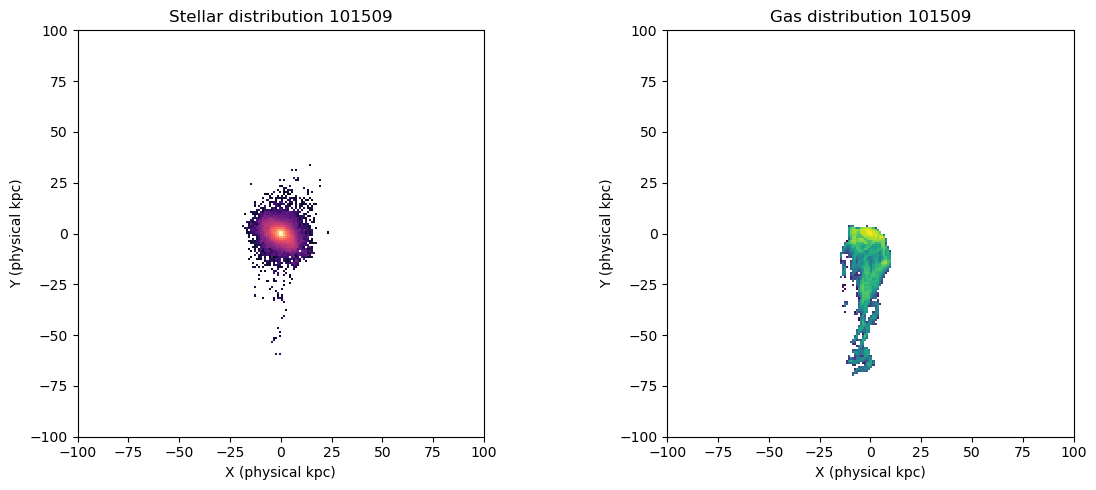

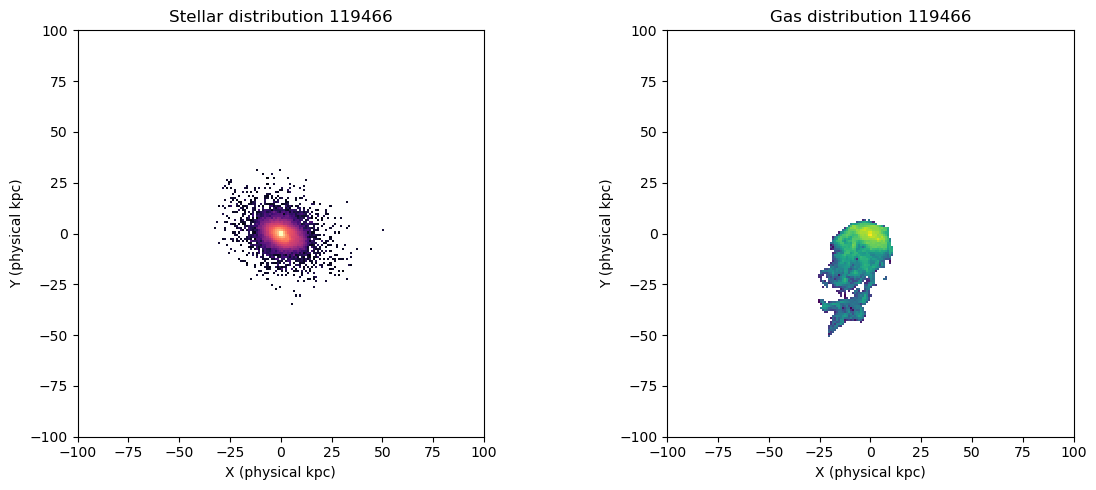

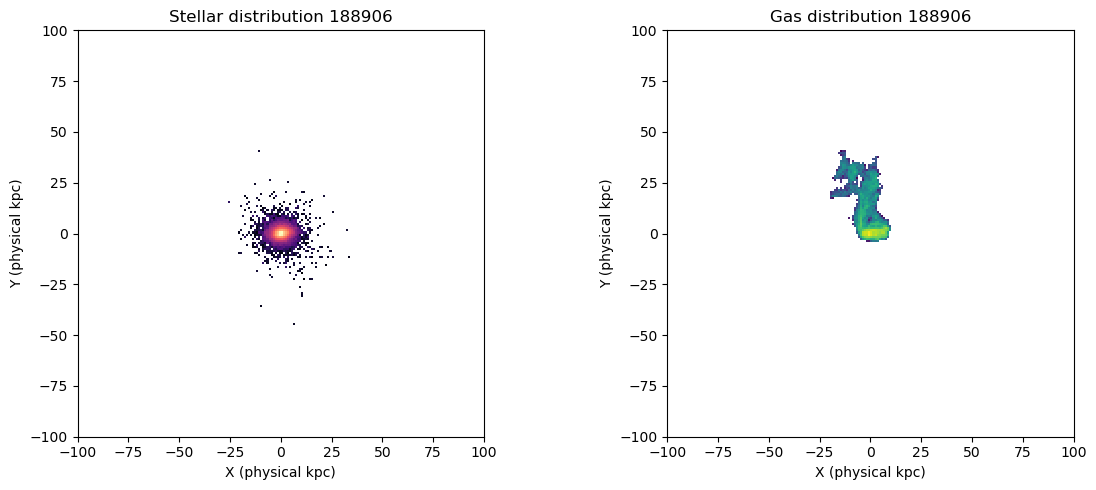

In [17]:
for i in range(len(finalcands)):
    galaxy_id = list(finalcands)[i]
    
    gas = il.snapshot.loadSubhalo(
        basePath, snapnum, galaxy_id, "gas",
        fields=["Coordinates", "Masses"]
    )

    stars = il.snapshot.loadSubhalo(
        basePath, snapnum, galaxy_id, "stars",
        fields=["Coordinates", "Masses"]
    )

    center = subhalos["SubhaloPos"][galaxy_id]
    boxsize = 35000

    gas_pos = gas["Coordinates"] - center
    star_pos = stars["Coordinates"] - center

    gas_pos -= boxsize * np.round(gas_pos / boxsize)
    star_pos -= boxsize * np.round(star_pos / boxsize)
    z = 0.1

    gas_pos = gas_pos / (h * (1 + z))
    star_pos = star_pos / (h * (1 + z))

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    #plt.subplot(int(str(len(finalcands)) + '2' + str(i)), title=f"Stellar distribution {galaxy_id}")
    #plt.hist
    #print(fig, axes)
    axes[0].hist2d(
        star_pos[:, 0],
        star_pos[:, 1],
        bins=200,
        range=[[-100, 100], [-100, 100]],
        weights=stars["Masses"],
        norm=LogNorm(),
        cmap="magma"
    )

    axes[0].set_title(f"Stellar distribution {galaxy_id}")

    axes[1].hist2d(
        gas_pos[:, 0],
        gas_pos[:, 1],
        bins=200,
        range=[[-100, 100], [-100, 100]],
        weights=gas["Masses"],
        norm=LogNorm(),
        cmap="viridis"
    )

    axes[1].set_title(f"Gas distribution {galaxy_id}")

    for ax in axes:
        ax.set_xlabel("X (physical kpc)")
        ax.set_ylabel("Y (physical kpc)")
        ax.set_aspect("equal")
    plt.savefig(f"Stellar and Gas Dist. {galaxy_id}.pdf", format="pdf")
    plt.tight_layout()
    plt.show()

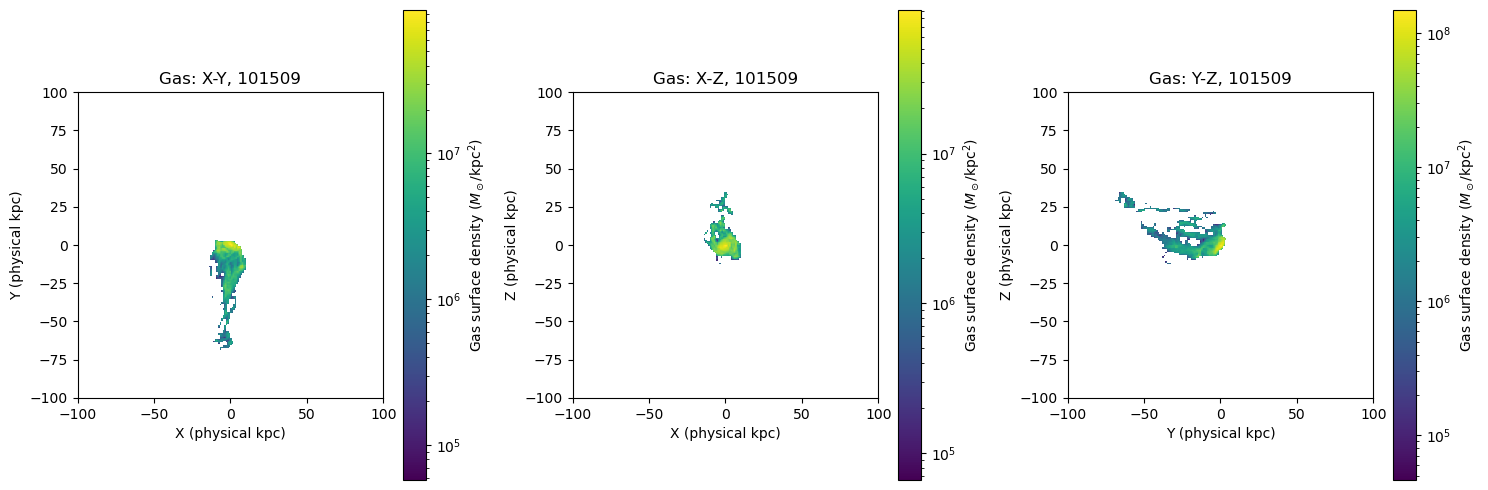

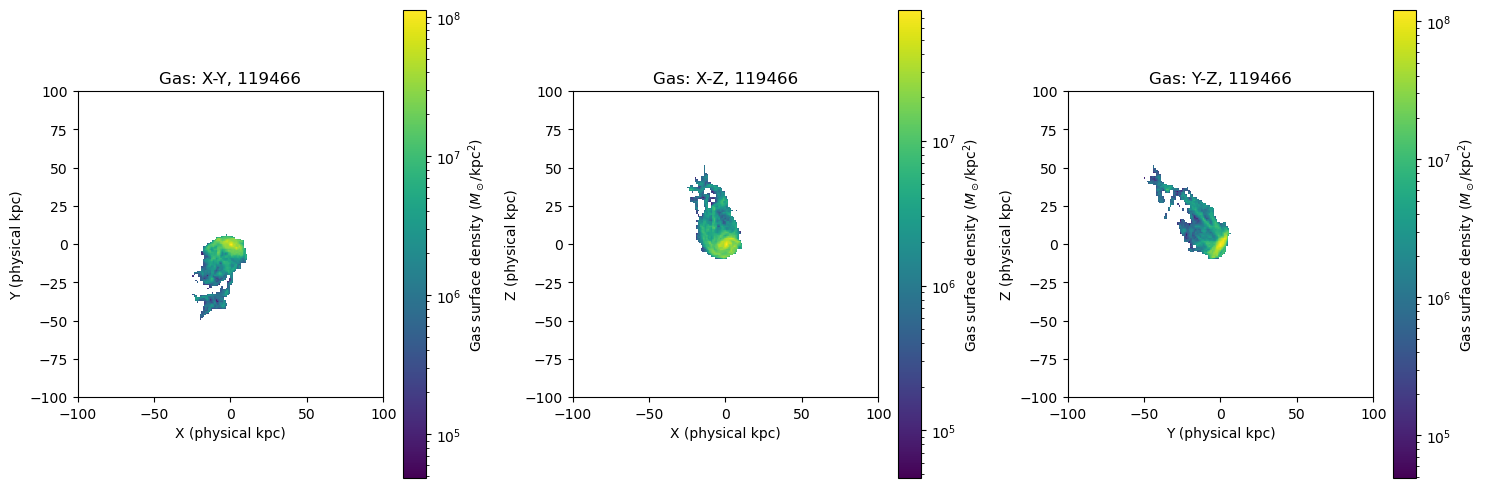

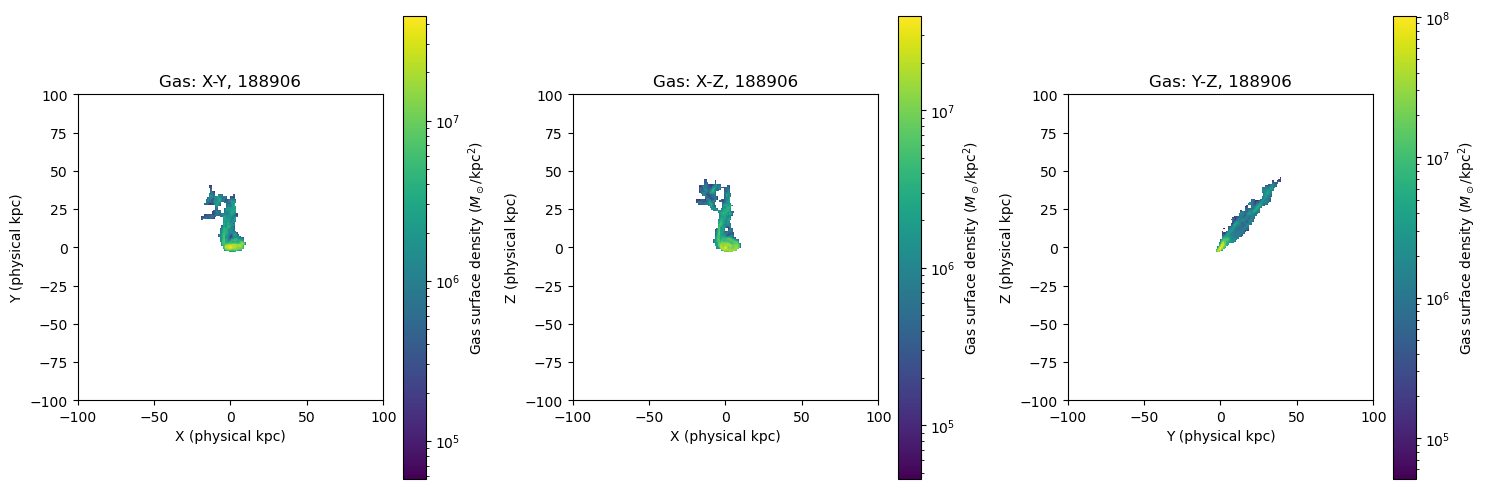

In [18]:
for galaxy_id in finalcands:

    galaxy_id = int(galaxy_id)

    # Load gas particles
    gas = il.snapshot.loadSubhalo(
        basePath, snapnum, galaxy_id, "gas",
        fields=["Coordinates", "Masses"]
    )

    # Galaxy centre
    center = subhalos["SubhaloPos"][galaxy_id]

    # Centre gas positions
    gas_pos = gas["Coordinates"] - center

    # Periodic boundary correction
    gas_pos -= boxsize * np.round(gas_pos / boxsize)

    # Convert to physical kpc
    gas_pos = gas_pos / (h * (1 + z))

    # Convert gas masses to solar masses
    gas_mass = gas["Masses"] * 1e10 / h

    projections = [(0, 1), (0, 2), (1, 2)]
    labels = ["X", "Y", "Z"]

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    for ax, (i, j) in zip(axes, projections):

        # Calculate projected gas mass
        hist, xedges, yedges = np.histogram2d(
            gas_pos[:, i],
            gas_pos[:, j],
            bins=200,
            range=[[-100, 100], [-100, 100]],
            weights=gas_mass
        )

        # Convert to gas surface density
        pixel_area = (
            (xedges[1] - xedges[0]) *
            (yedges[1] - yedges[0])
        )

        surface_density = hist / pixel_area

        # Plot surface density
        image = ax.imshow(
            np.ma.masked_less_equal(surface_density.T, 0),
            origin="lower",
            extent=[-100, 100, -100, 100],
            norm=LogNorm(),
            cmap="viridis"
        )

        ax.set_title(
            f"Gas: {labels[i]}-{labels[j]}, {galaxy_id}"
        )

        ax.set_xlabel(f"{labels[i]} (physical kpc)")
        ax.set_ylabel(f"{labels[j]} (physical kpc)")

        ax.set_xlim(-100, 100)
        ax.set_ylim(-100, 100)
        ax.set_aspect("equal")

        fig.colorbar(
            image,
            ax=ax,
            label=r"Gas surface density ($M_\odot$/kpc$^2$)"
        )

    plt.tight_layout()
    plt.show()

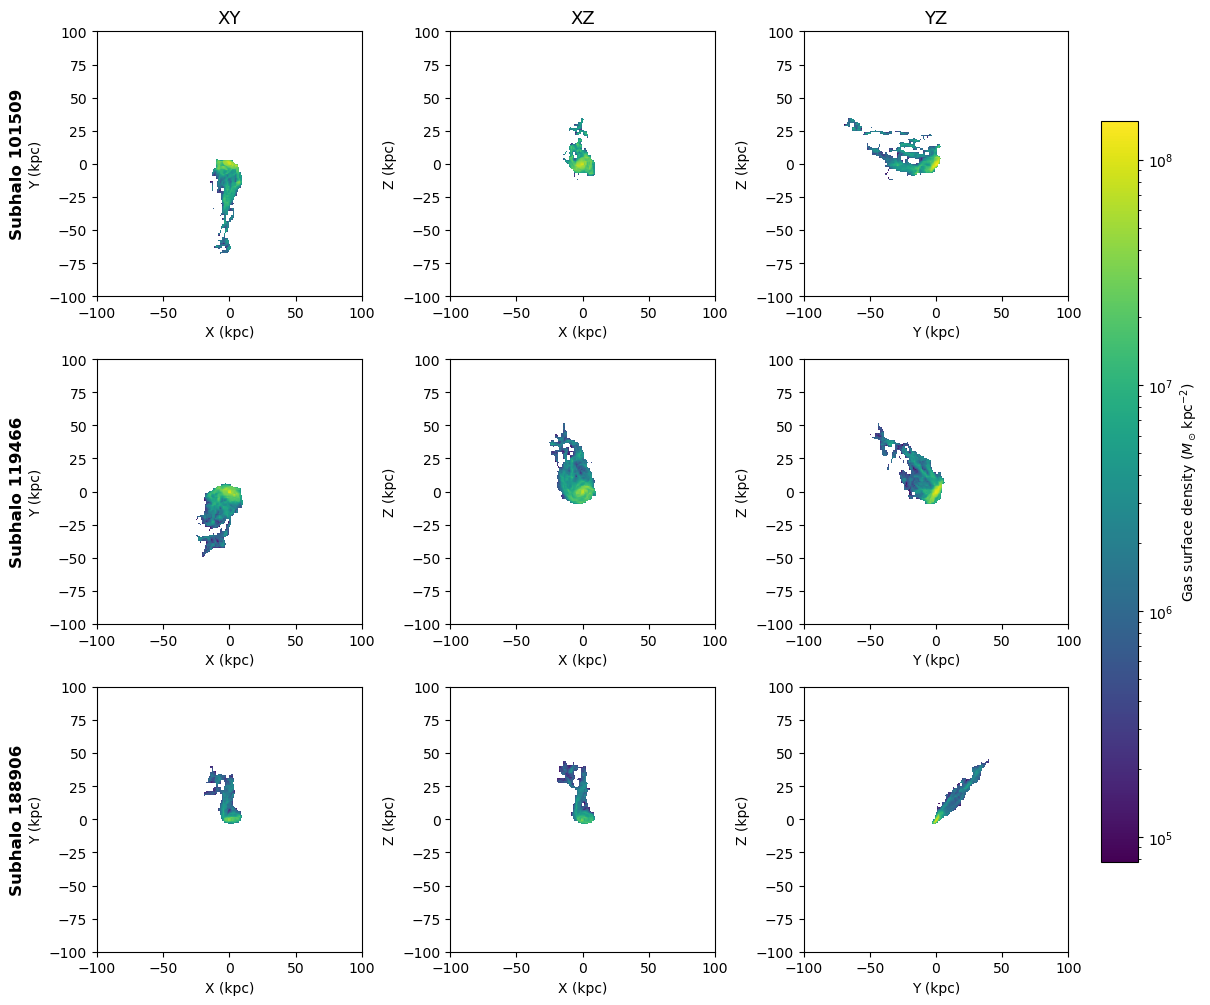

In [19]:


projections = [(0, 1), (0, 2), (1, 2)]
labels = ["X", "Y", "Z"]
galaxy_ids = [int(gid) for gid in finalcands]

fig, axes = plt.subplots(
    len(galaxy_ids), 3,
    figsize=(12, 10),
    layout="constrained"
)

# First collect the surface densities to determine
# a consistent colour scale across all galaxies
maps = {}

for galaxy_id in galaxy_ids:

    gas = il.snapshot.loadSubhalo(
        basePath, snapnum, galaxy_id, "gas",
        fields=["Coordinates", "Masses"]
    )

    center = subhalos["SubhaloPos"][galaxy_id]

    gas_pos = gas["Coordinates"].astype(float) - center
    gas_pos -= boxsize * np.round(gas_pos / boxsize)
    gas_pos /= h * (1 + z)

    gas_mass = gas["Masses"] * 1e10 / h

    for col, (i, j) in enumerate(projections):

        hist, xedges, yedges = np.histogram2d(
            gas_pos[:, i], gas_pos[:, j],
            bins=200,
            range=[[-100, 100], [-100, 100]],
            weights=gas_mass
        )

        pixel_area = (xedges[1] - xedges[0]) * (yedges[1] - yedges[0])
        maps[galaxy_id, col] = hist.T / pixel_area

# Shared normalization
positive = np.concatenate([
    m[m > 0] for m in maps.values()
])

norm = LogNorm(
    vmin=np.percentile(positive, 1),
    vmax=positive.max()
)
for col, title in enumerate(["XY", "XZ", "YZ"]):
    axes[0, col].set_title(title, fontsize=13)
# Plot all nine panels
for row, galaxy_id in enumerate(galaxy_ids):
    for col, (i, j) in enumerate(projections):

        ax = axes[row, col]

        image = ax.imshow(
            np.ma.masked_less_equal(maps[galaxy_id, col], 0),
            origin="lower",
            extent=[-100, 100, -100, 100],
            norm=norm,
            cmap="viridis"
        )

        ax.set_xlabel(f"{labels[i]} (kpc)")
        ax.set_ylabel(f"{labels[j]} (kpc)")
        ax.set_aspect("equal")

        # Galaxy ID on the leftmost panel of each row
        if col == 0:
            ax.annotate(
                f"Subhalo {galaxy_id}",
                xy=(-0.30, 0.5),
                xycoords="axes fraction",
                rotation=90,
                ha="center",
                va="center",
                fontsize=12,
                fontweight="bold",
                annotation_clip=False)
# One colourbar for the whole figure
fig.colorbar(
    image,
    ax=axes.ravel().tolist(),
    label=r"Gas surface density ($M_\odot\,\mathrm{kpc}^{-2}$)",
    shrink=0.8,
    pad=0.02
)

fig.savefig(
    "galaxy_gas_morphology.pdf",
    bbox_inches="tight"
)

plt.show()

<h2>Getting Gas, Stellar, and SFR data</h2>

In [20]:
gas_fields = [
    "Coordinates",
    "Masses",
    "Density",
    "StarFormationRate",
    "NeutralHydrogenAbundance",
    "Velocities", 
    "InternalEnergy"]

star_fields = [
    "Coordinates",
    "Masses",
    "GFM_StellarFormationTime",
    "Velocities"]

def get_gas(galaxy_id):
    z = 0.1
    a = 1/(1+z)
    density_factor = 1e10 * h**2 * (1 + z)**3
    host_id = int(subhalos["SubhaloGrNr"][galaxy_id])
    gas = il.snapshot.loadSubhalo(basePath,
                                  snapnum,
                                  galaxy_id,
                                  "gas",
                                  fields = gas_fields)
    center = subhalos["SubhaloPos"][galaxy_id]
    pos = gas["Coordinates"] - center
    pos -= boxsize * np.round(pos/boxsize)
    pos = pos * a / h
    mass = gas["Masses"] * 1e10 / h
    vel = gas["Velocities"] / np.sqrt(a)
    
    df  = pd.DataFrame({ 
        "x": pos[:, 0],
        "y": pos[:, 1],
        "z": pos[:, 2],
        "Mass": mass,
        "vx": vel[:, 0],
        "vy": vel[:, 1],
        "vz": vel[:, 2]})
    df["SFR"] = gas["StarFormationRate"]
    df["InternalEnergy"] = gas["InternalEnergy"]
    df["Density"] = gas["Density"] * density_factor
    df["Neutral Hydrogen Abundance"] = gas["NeutralHydrogenAbundance"]
    
    
    return df


def get_stars(galaxy_id):
    galaxy_id = int(galaxy_id)

    h = 0.6774
    z = 0.1
    a = 1 / (1 + z)
    boxsize = 35000.0

    star_fields = [
        "Coordinates",
        "Masses",
        "Velocities",
        "GFM_StellarFormationTime"
    ]

    stars = il.snapshot.loadSubhalo(
        basePath,
        snapnum,
        galaxy_id,
        "stars",
        fields=star_fields
    )

    columns = [
        "x", "y", "z", "Mass",
        "vx", "vy", "vz",
        "FormationTime"
    ]

    if isinstance(stars, dict):
        if len(stars["Masses"]) == 0:
            return pd.DataFrame(columns=columns)
    else:
        return pd.DataFrame(columns=columns)

    center = subhalos["SubhaloPos"][galaxy_id]

    pos = (
        stars["Coordinates"].astype(np.float64)
        - center
    )

    pos -= boxsize * np.round(pos / boxsize)
    pos *= a / h

    vel = stars["Velocities"] / np.sqrt(a)
    mass = stars["Masses"] * 1e10 / h

    formation = stars["GFM_StellarFormationTime"]

    # Exclude wind particles
    mask = formation > 0

    return pd.DataFrame({
        "x": pos[mask, 0],
        "y": pos[mask, 1],
        "z": pos[mask, 2],
        "Mass": mass[mask],
        "vx": vel[mask, 0],
        "vy": vel[mask, 1],
        "vz": vel[mask, 2],
        "FormationTime": formation[mask]
    })

gasses = {}
stars = {}
for galaxy_id in finalcands:
    gasses[galaxy_id] = get_gas(galaxy_id)
    stars[galaxy_id] = get_stars(galaxy_id)


In [21]:
sf_gasses = {
    int(galaxy_id): pd.read_csv(
        f"./sfr_results/sf_gas_{int(galaxy_id)}.csv")
    for galaxy_id in finalcands
}

<h2> Gas Density Analysis </h2>

In [22]:
h = 0.6774
z = 0.1
def density_outside_disk(galaxy_id):
    gas_df = gasses[galaxy_id]

    rstar = (
        subhalos["SubhaloHalfmassRadType"][galaxy_id, 4]
        / (h * (1 + z)))



    print(f"{galaxy_id} stellar half-mass radius:", rstar)

    radius = np.sqrt(
        gas_df["x"]**2 +
        gas_df["y"]**2 +
        gas_df["z"]**2
    )

    outside_disk = radius > 2 * rstar

    tail_densities = gas_df["Density"][outside_disk.to_numpy()]
    print("Median density outside disk:", np.median(tail_densities))
    print("Maximum density outside disk:", np.max(tail_densities))
    return tail_densities


In [23]:
import ipympl
%matplotlib widget


def threeDplot(galaxy_id, extra=None):
    gas_plot = gasses[galaxy_id]
    sf_plot = sf_gasses[galaxy_id]
    stars_plot = stars[galaxy_id]
    gas_sample = gas_plot.sample(
        n=min(20000, len(gas_plot)),
        random_state=42)

    stars_sample = stars_plot.sample(
        n=min(5000, len(stars_plot)),
        random_state=42)

    fig = plt.figure(figsize=(7.5, 5.5))

    ax = fig.add_subplot(111, projection='3d')

    # gas associated with the subhalo
    ax.scatter(
        gas_sample['x'],
        gas_sample['y'],
        gas_sample['z'],
        s=1,
        c='blue',
        alpha=0.2,
        label='Gas')

    # stellar particles
    ax.scatter(
        stars_sample['x'],
        stars_sample['y'],
        stars_sample['z'],
        s=2,
        c='orange',
        alpha=0.5,
        label='Stars')

    # star-forming gas from the spatial search
    ax.scatter(
        sf_plot['x'],
        sf_plot['y'],
        sf_plot['z'],
        s=5,
        c='red',
        alpha=1,
        label='Star-forming gas')

    # optional overdensity location (used for playground-exploration)
    if extra is not None:
        ax.scatter(
            extra[0],
            extra[1],
            extra[2],
            s=50,
            c='magenta',
            marker='*',
            label='Possible overdensity')

    ax.set_xlabel('X (physical kpc)')
    ax.set_ylabel('Y (physical kpc)')
    ax.set_zlabel('Z (physical kpc)')

    ax.set_title(str(galaxy_id))

    # use equal limits on all three axes
    max_extent = 100

    ax.set_xlim(-max_extent, max_extent)
    ax.set_ylim(-max_extent, max_extent)
    ax.set_zlim(-max_extent, max_extent)

    ax.set_box_aspect((1, 1, 1))

    ax.legend()
    plt.show()


In [24]:
def candidate_peaks(galaxy_id):
    gas_df = gasses[galaxy_id]
    # construct 3D gas distribution
    edges = np.linspace(-100, 100, 81)

    pos = gas_df[["x", "y", "z"]].to_numpy()

    mass_grid, _ = np.histogramdd(
        pos,
        bins=[edges, edges, edges],
        weights=gas_df["Mass"])

    # gas density (Msun/kpc^3)
    voxel_volume = (edges[1] - edges[0])**3
    density_grid = mass_grid / voxel_volume

    # smoothing
    smooth_density = gaussian_filter(
        density_grid,
        sigma=1)

    local_max = (
        smooth_density ==
        maximum_filter(smooth_density, size=5))

    # exclude the galaxy's inner stellar region
    h = 0.6774
    a = 1 / 1.1

    rstar = (
        subhalos["SubhaloHalfmassRadType"][galaxy_id, 4]
        * a / h
    )

    centres = (edges[:-1] + edges[1:]) / 2

    X, Y, Z = np.meshgrid(
        centres, centres, centres,
        indexing="ij"
    )

    radius = np.sqrt(X**2 + Y**2 + Z**2)
    outside_disk = radius > 2 * rstar

    # Exploratory density threshold
    tail_values = smooth_density[outside_disk]

    threshold = np.percentile(tail_values, 99)

    # candidate peaks
    peak_mask = (
        local_max &
        outside_disk &
        (smooth_density > threshold)
    )

    peak_indices = np.argwhere(peak_mask)

    peak_positions = centres[peak_indices]

    print(f"Number of candidate peaks for {galaxy_id}:", len(peak_positions))
    print(peak_positions[:10])
    if len(peak_positions) > 0:
        for peak in peak_positions:
            xc, yc, zc = peak[0], peak[1], peak[2]

            distance = np.sqrt(
                (gas_df["x"] - xc)**2 +
                (gas_df["y"] - yc)**2 +
                (gas_df["z"] - zc)**2)

            clump = gas_df[distance < 3]
            mass = clump["Mass"].sum()
            sfr = clump["SFR"].sum()
            if sfr > 0:
                print("Coordinates: ", xc, yc, zc)
                print("Gas cells:", len(clump))
                print(f"Gas mass: {mass:.2e} Msun")
                print(f"SFR: {sfr:.2e} Msun/yr")
    return peak_positions

In [25]:
def plot_gas_sf_maps(galaxy_id, bins=200, plot_range=100):
    gas_df = gasses[galaxy_id]
    sf_df = sf_gasses[galaxy_id]

    projections = [
        ("x", "y", "XY"),
        ("x", "z", "XZ"),
        ("y", "z", "YZ")
    ]

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    for ax, (xcol, ycol, name) in zip(axes, projections):

        hist, xe, ye = np.histogram2d(
            gas_df[xcol],
            gas_df[ycol],
            bins=bins,
            range=[[-plot_range, plot_range], [-plot_range, plot_range]],
            weights=gas_df["Mass"]
        )

        pixel_area = (xe[1] - xe[0]) * (ye[1] - ye[0])
        surface_density = hist / pixel_area

        im = ax.imshow(
            np.ma.masked_less_equal(surface_density.T, 0),
            origin="lower",
            extent=[-plot_range, plot_range, -plot_range, plot_range],
            norm=LogNorm(),
            cmap="viridis"
        )

        if len(sf_df) > 0:
            ax.scatter(
                sf_df[xcol],
                sf_df[ycol],
                s=4,
                c="red",
                alpha=0.5,
                label="Star-forming gas"
            )

        ax.scatter(0, 0, c="white", marker="+", s=80, linewidths=1.5, label="Galaxy centre")

        ax.set_title(f"{galaxy_id} — {name}")
        ax.set_xlabel(f"{xcol.upper()} (physical kpc)")
        ax.set_ylabel(f"{ycol.upper()} (physical kpc)")
        ax.set_xlim(-plot_range, plot_range)
        ax.set_ylim(-plot_range, plot_range)
        ax.set_aspect("equal")
        ax.legend()

        fig.colorbar(
            im,
            ax=ax,
            label=r"Gas surface density ($M_\odot/\mathrm{kpc}^2$)"
        )

    plt.tight_layout()
    plt.show()

In [26]:

display(filter7[['Subhalo ID','Subhalo Total Mass', 'Subhalo Total Stellar Mass', 'Jellyfish Score', 'R200 ratio', 'Mgas/Mstars', 'rh*/rhgas']])

,Subhalo ID,Subhalo Total Mass,Subhalo Total Stellar Mass,Jellyfish Score,R200 ratio,Mgas/Mstars,rh*/rhgas
7,101509,2.948565,0.373207,0.955595,0.306950,1.225702,0.197927
8,119466,6.427191,0.641981,0.873870,0.358177,0.748122,0.253467
13,188906,3.465622,0.220393,0.946595,0.468407,0.574915,0.285220


In [27]:
def far_particles(galaxy_id):
    sfgas = sf_gasses[galaxy_id]
    z = 0.1
    a = 1 + z
    r_hsmass = filter7.loc[filter7['Subhalo ID'] == galaxy_id, 'Subhalo Half Stellar Mass Radius'].iloc[0] / a /h
    return sfgas.loc[np.sqrt(sfgas['x']**2 + sfgas['y']**2 + sfgas['z']**2) >= 2 * r_hsmass]

In [28]:
for galaxy_id in finalcands:
    far = far_particles(galaxy_id)
    print(f"Subhalo {galaxy_id}")
    print(f'Number of starforming gas cells outside radius:{len(far)}')
    print("Star-forming gas cells outside radius:", len(far))
    print("Total SFR:", far["SFR"].sum(), "Msun/yr")

Subhalo 101509
Number of starforming gas cells outside radius:29385
Star-forming gas cells outside radius: 29385
Total SFR: 1.1339794077801 Msun/yr
Subhalo 119466
Number of starforming gas cells outside radius:22519
Star-forming gas cells outside radius: 22519
Total SFR: 0.8516663953353999 Msun/yr
Subhalo 188906
Number of starforming gas cells outside radius:2591
Star-forming gas cells outside radius: 2591
Total SFR: 0.09076654182350001 Msun/yr


In [29]:
from matplotlib.colors import LogNorm

def plot_sfr_map(galaxy_id):

    sf = far_particles(galaxy_id)

    if sf.empty:
        print("No star-forming cells selected.")
        return

    projections = [
        ("x", "y", "XY"),
        ("x", "z", "XZ"),
        ("y", "z", "YZ")
    ]

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    for ax, (xcol, ycol, name) in zip(axes, projections):

        hist, xedges, yedges = np.histogram2d(
            sf[xcol],
            sf[ycol],
            bins=100,
            range=[[-100, 100], [-100, 100]],
            weights=sf["SFR"]
        )

        # Convert to SFR surface density
        pixel_area = (
            (xedges[1] - xedges[0]) *
            (yedges[1] - yedges[0])
        )

        sfr_density = hist / pixel_area

        im = ax.imshow(
            np.ma.masked_less_equal(sfr_density.T, 0),
            origin="lower",
            extent=[-100, 100, -100, 100],
            cmap="magma",
            norm=LogNorm()
        )

        ax.scatter(0, 0, marker="+", c="cyan", s=80)

        ax.set_title(name)
        ax.set_xlabel(f"{xcol.upper()} (kpc)")
        ax.set_ylabel(f"{ycol.upper()} (kpc)")
        ax.set_aspect("equal")

        fig.colorbar(
            im,
            ax=ax,
            label=r"SFR surface density ($M_\odot$/yr/kpc$^2$)"
        )

    plt.suptitle(f"Extended Star Formation — {galaxy_id}")
    plt.tight_layout()
    plt.show()



In [30]:
from sklearn.cluster import DBSCAN

def find_sf_groups(galaxy_id, eps=2, min_samples=10):

    sf = far_particles(galaxy_id).copy()

    positions = sf[["x", "y", "z"]].to_numpy()

    if len(positions) == 0:
        return sf

    clustering = DBSCAN(
        eps=eps,
        min_samples=min_samples
    )

    sf["Group"] = clustering.fit_predict(positions)

    # -1 means the cell wasn't assigned to a group
    groups = sf[sf["Group"] >= 0].groupby("Group")

    summary = groups.agg(
        Cells=("Mass", "size"),
        Gas_Mass=("Mass", "sum"),
        SFR=("SFR", "sum"),
        X=("x", "mean"),
        Y=("y", "mean"),
        Z=("z", "mean")
    )

    summary = summary.sort_values(
        "SFR",
        ascending=False
    )

    print(f"Subhalo {galaxy_id}")
    print("Number of groups:", len(summary))

    display(summary)

    return sf, summary


Subhalo 101509

Subhalo 119466

Subhalo 188906


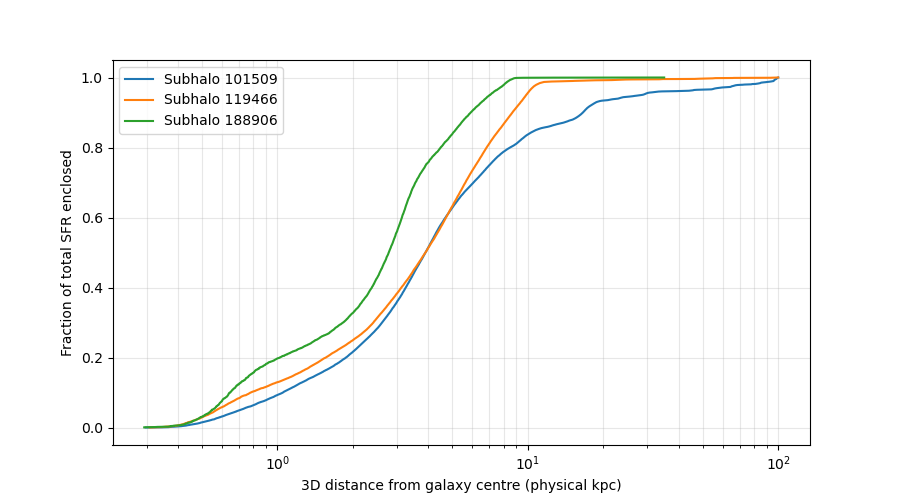

In [31]:
def cumulative_fraction_sfr(galaxy_id, show=True):

    sf_gas = sf_gasses[galaxy_id]
    r = np.sqrt(
        sf_gas["x"]**2 +
        sf_gas["y"]**2 +
        sf_gas["z"]**2
    ).to_numpy()

    sfr = sf_gas["SFR"].to_numpy()

    # Sort cells by distance
    order = np.argsort(r)

    r_sorted = r[order]
    sfr_sorted = sfr[order]

    # Cumulative fraction of total SFR
    cumulative = np.cumsum(sfr_sorted)
    cumulative /= cumulative[-1]
    print(f"\nSubhalo {galaxy_id}")
    #for radius in [10, 20, 30, 40, 50, 75]:
    #    mask = r > radius

       # print(
       #     f"Beyond {radius} kpc: "
       #     f"{mask.sum()} cells, "
       #3     f"SFR = {sf_gas.loc[mask, 'SFR'].sum():.5f} Msun/yr"
        #)
    if show:

        fig, ax = plt.subplots(figsize=(9, 5))
        ax.plot(
            r_sorted,
            cumulative,
            label=f"Subhalo {galaxy_id}"
        )


        ax.set_xlabel("3D distance from galaxy centre (physical kpc)")
        ax.set_ylabel("Fraction of total SFR enclosed")
        ax.set_xlim(0, 100)
        ax.set_ylim(0, 1.02)
    #    ax.legend()
        ax.grid(alpha=0.3)
        ax.legend()
        plt.show()
    else:
        plt.plot(r_sorted, cumulative, label=f"Subhalo {galaxy_id}")
        plt.xlabel("3D distance from galaxy centre (physical kpc)")
        plt.ylabel("Fraction of total SFR enclosed")
        plt.grid(alpha = 0.3, which='both')
plt.figure(figsize=(9, 5))
for galaxy_id in finalcands:

    cumulative_fraction_sfr(galaxy_id, False)
plt.xscale('log')

plt.legend()
plt.savefig('SFR_from_galaxy_centre.pdf',bbox_inches="tight", format='pdf') 
plt.show()

Putting it all together to find overdensities


Subhalo 101509


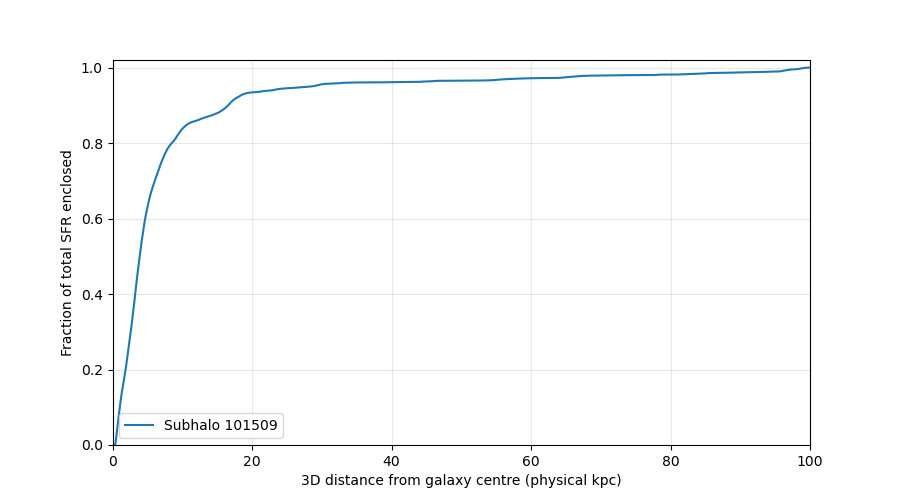

Subhalo 101509
Number of groups: 54


,Cells,Gas_Mass,SFR,X,Y,Z
Group,,,,,,
17,24849,2.274177e+09,1.000255,-1.073537,-2.285653,0.329721
49,546,4.904306e+07,0.017071,-2.986054,-22.496181,14.062503
28,419,3.667749e+07,0.013027,-23.885237,-89.711690,27.645423
24,373,3.136075e+07,0.011225,-2.909917,-51.454765,22.712015
51,331,3.040700e+07,0.009646,-1.626578,-29.855579,-0.898311
50,247,2.218754e+07,0.007108,0.815736,-20.551843,7.433917
26,211,1.893509e+07,0.006046,-2.386990,-15.116222,16.917470
42,165,1.564247e+07,0.005286,-3.422512,-44.760486,9.883891
29,156,1.393646e+07,0.004355,-15.552228,-62.366775,12.020004


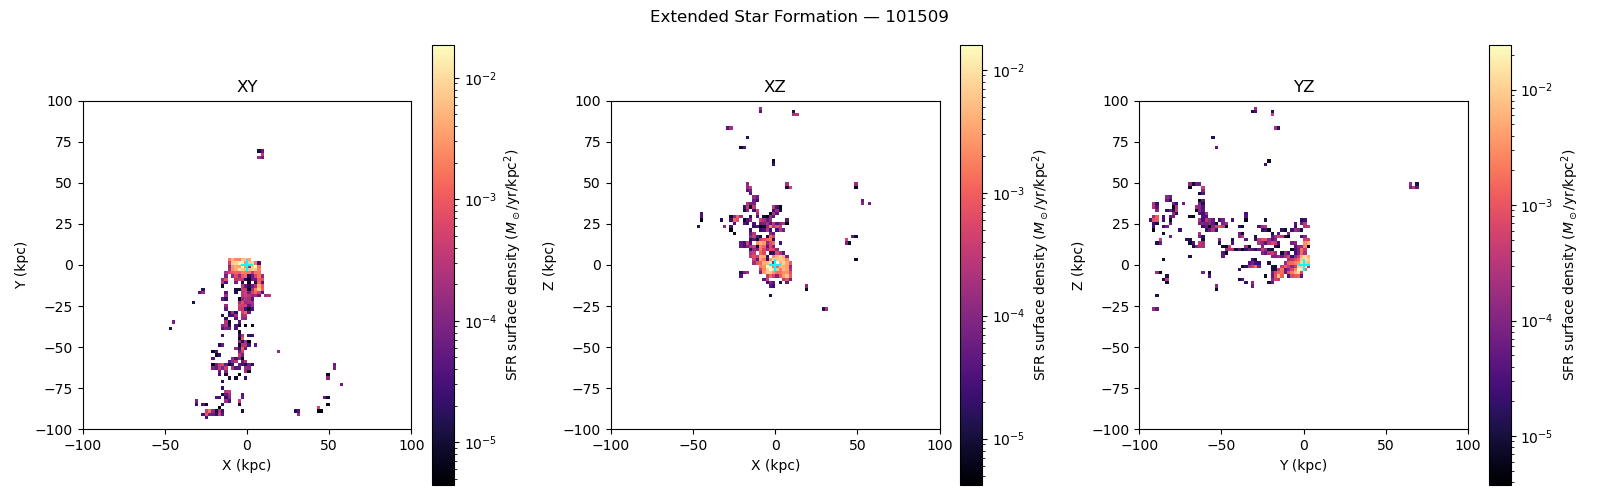

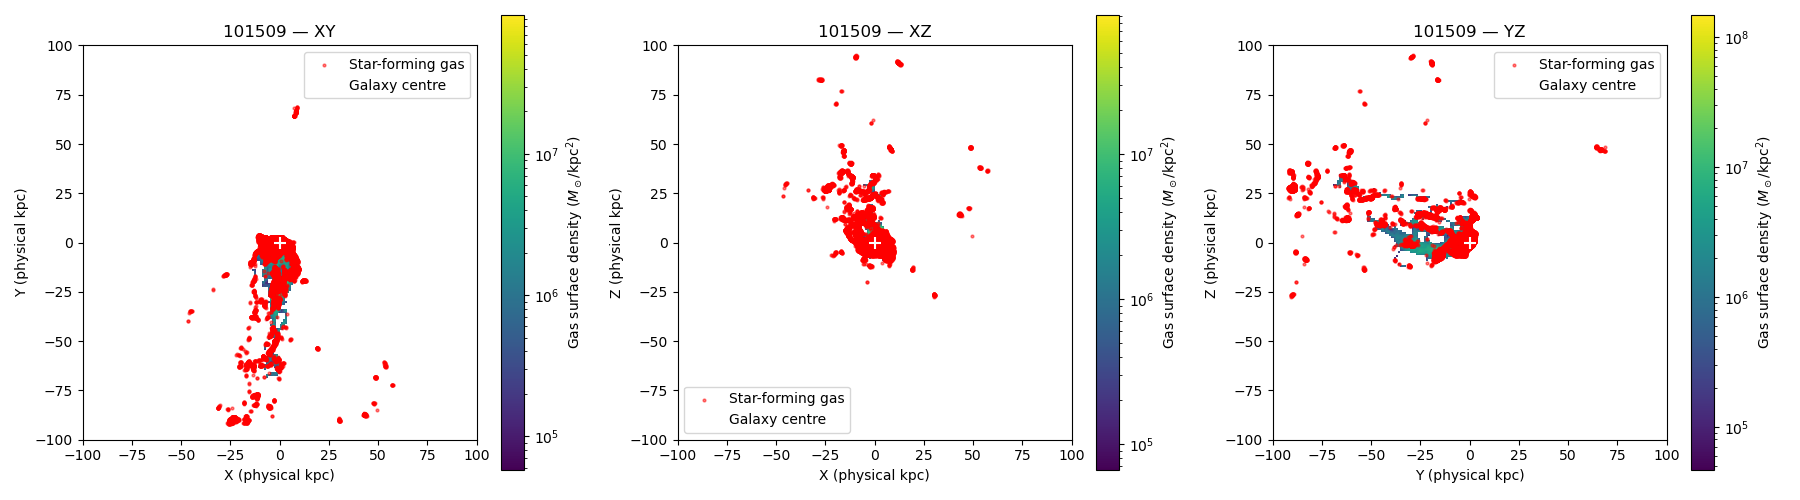

Number of candidate peaks for 101509: 7
[[-13.75 -18.75   8.75]
 [ -3.75 -51.25  23.75]
 [ -3.75 -43.75   8.75]
 [ -3.75 -23.75  13.75]
 [ -1.25 -58.75  28.75]
 [ -1.25 -28.75  -1.25]
 [  6.25 -13.75  -6.25]]
Coordinates:  -13.75 -18.75 8.75
Gas cells: 171
Gas mass: 1.68e+07 Msun
SFR: 6.82e-04 Msun/yr
Coordinates:  -3.75 -51.25 23.75
Gas cells: 441
Gas mass: 3.99e+07 Msun
SFR: 7.29e-03 Msun/yr
Coordinates:  -3.75 -43.75 8.75
Gas cells: 383
Gas mass: 3.59e+07 Msun
SFR: 3.79e-03 Msun/yr
Coordinates:  -3.75 -23.75 13.75
Gas cells: 924
Gas mass: 8.71e+07 Msun
SFR: 1.01e-02 Msun/yr
Coordinates:  -1.25 -58.75 28.75
Gas cells: 489
Gas mass: 4.55e+07 Msun
SFR: 1.31e-03 Msun/yr
Coordinates:  -1.25 -28.75 -1.25
Gas cells: 1390
Gas mass: 1.30e+08 Msun
SFR: 7.99e-03 Msun/yr
Coordinates:  6.25 -13.75 -6.25
Gas cells: 2010
Gas mass: 1.91e+08 Msun
SFR: 5.03e-02 Msun/yr
101509 stellar half-mass radius: 1.742414292030571
Median density outside disk: 2814074.0
Maximum density outside disk: 59369272.0


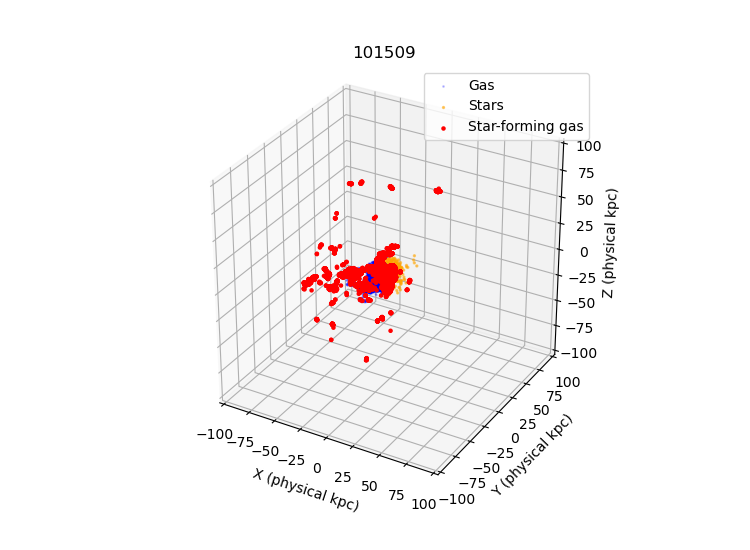


Subhalo 119466


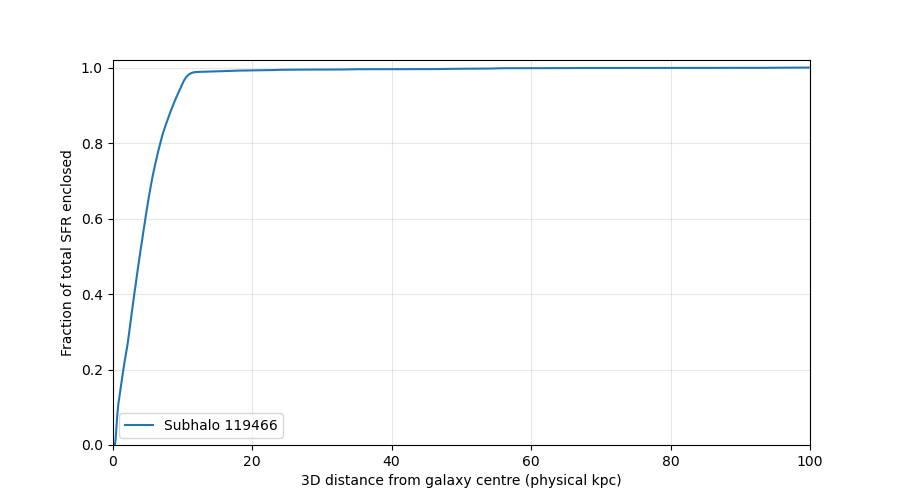

Subhalo 119466
Number of groups: 18


,Cells,Gas_Mass,SFR,X,Y,Z
Group,,,,,,
7,21734,1.980975e+09,0.829304,0.833301,-1.059064,-1.421571
12,112,1.164856e+07,0.003408,-8.042291,-4.497076,16.791903
6,92,8.047351e+06,0.002510,-14.303642,-3.202838,16.881237
13,55,5.849160e+06,0.001778,-14.876527,-1.963710,6.262806
3,60,5.585834e+06,0.001748,-1.907223,-17.587357,28.683415
15,61,5.440068e+06,0.001657,-22.411547,-35.335926,35.778535
4,48,4.104570e+06,0.001292,-6.927852,-12.074387,44.798983
2,44,3.527103e+06,0.001054,9.398602,-1.837552,47.495417
11,34,3.269204e+06,0.001001,-11.261280,-9.139610,1.470254


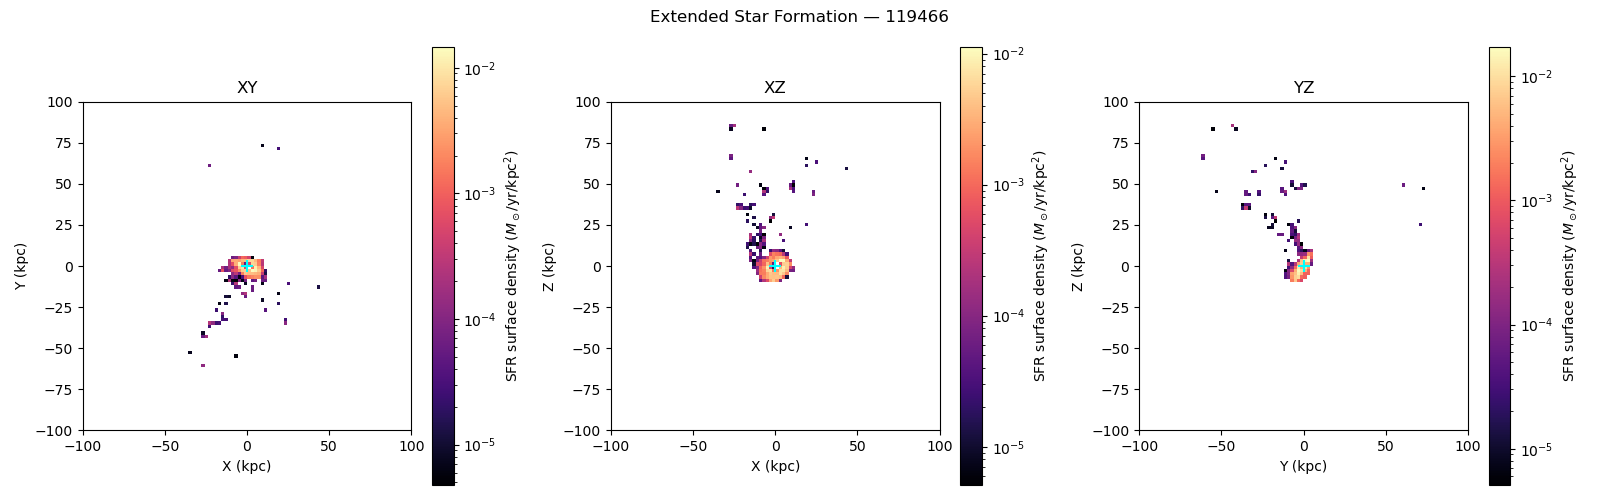

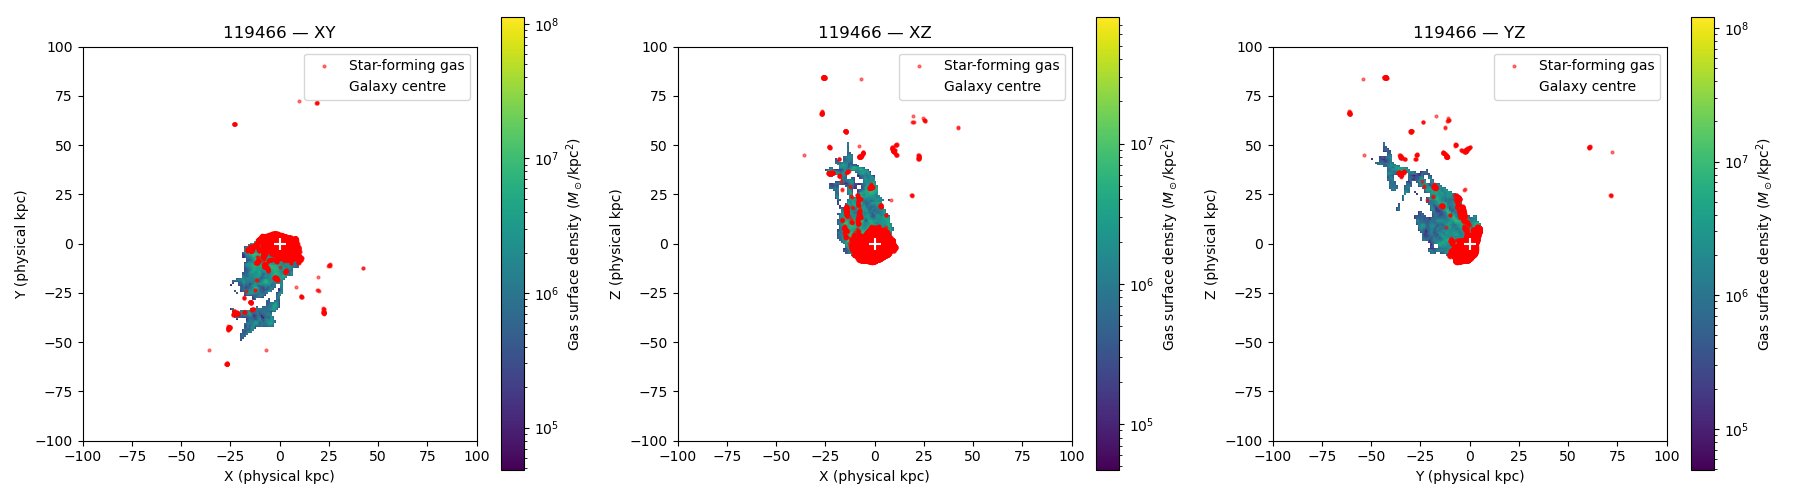

Number of candidate peaks for 119466: 4
[[-21.25 -36.25  36.25]
 [-11.25 -23.75   8.75]
 [ -3.75 -33.75  26.25]
 [ -1.25 -16.25  26.25]]
Coordinates:  -21.25 -36.25 36.25
Gas cells: 390
Gas mass: 3.70e+07 Msun
SFR: 1.62e-03 Msun/yr
Coordinates:  -1.25 -16.25 26.25
Gas cells: 568
Gas mass: 5.50e+07 Msun
SFR: 9.33e-04 Msun/yr
119466 stellar half-mass radius: 2.1322760556501015
Median density outside disk: 1887125.2
Maximum density outside disk: 37719552.0


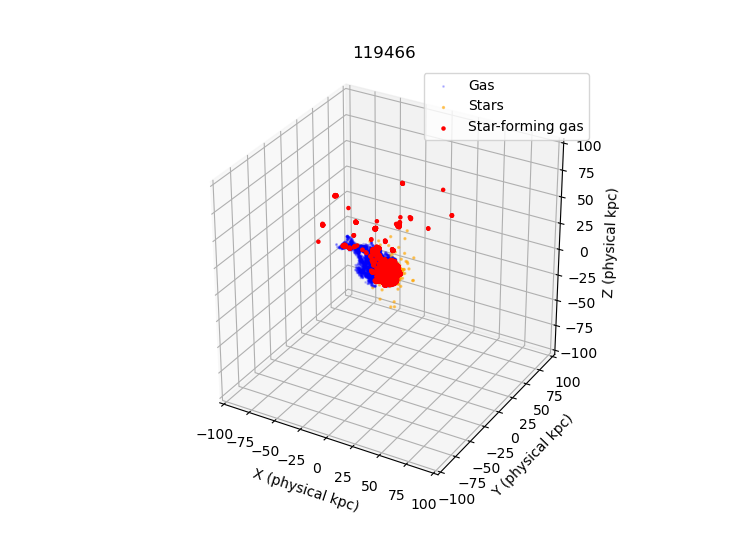


Subhalo 188906


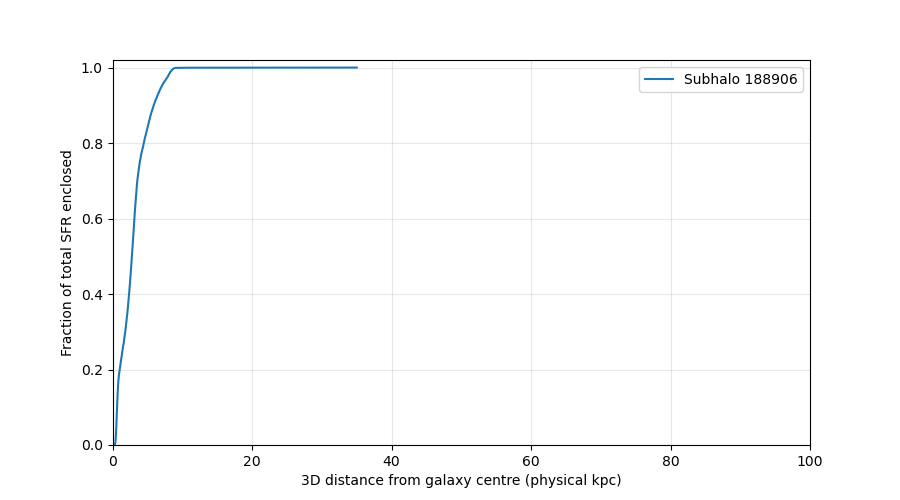

Subhalo 188906
Number of groups: 1


,Cells,Gas_Mass,SFR,X,Y,Z
Group,,,,,,
0,2578,2.538820e+08,0.090371,4.528146,0.324063,-0.216933


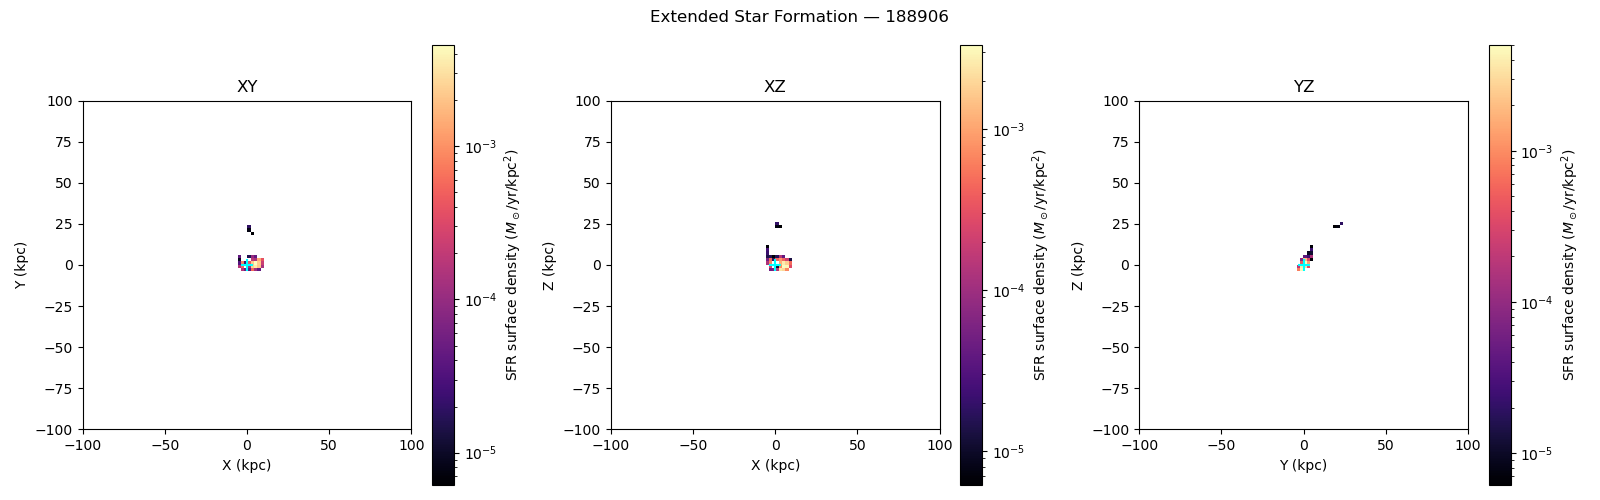

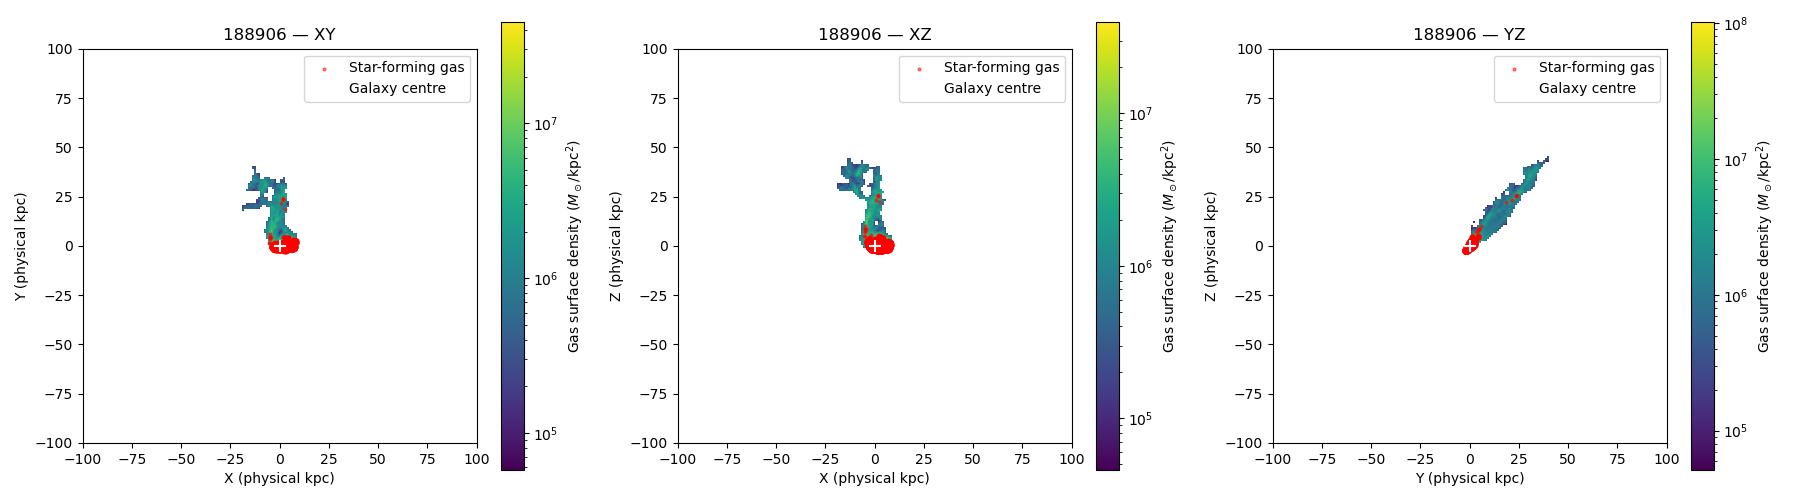

Number of candidate peaks for 188906: 2
[[-8.75 31.25 36.25]
 [ 1.25 23.75 26.25]]
Coordinates:  1.25 23.75 26.25
Gas cells: 470
Gas mass: 4.52e+07 Msun
SFR: 7.78e-05 Msun/yr
188906 stellar half-mass radius: 1.8534542400326217
Median density outside disk: 650957.56
Maximum density outside disk: 15811179.0


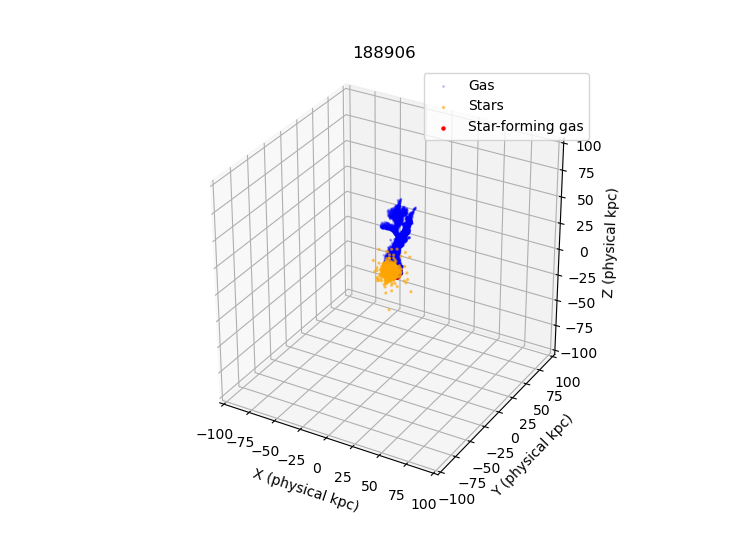

In [32]:
for galaxy_id in finalcands:
    cumulative_fraction_sfr(galaxy_id)
    find_sf_groups(galaxy_id)
    plot_sfr_map(galaxy_id)
    plot_gas_sf_maps(galaxy_id)
    candidate_peaks(galaxy_id)
    density_outside_disk(galaxy_id)
    threeDplot(galaxy_id)

<h2> Peaks Analysis </h2>

In [33]:
gas_df = gasses[101509]
positions = gas_df[["x", "y", "z"]].to_numpy()
masses = gas_df["Mass"].to_numpy()

def density_contrast(center, r_inner=3, r_outer=6):
    center = np.asarray(center, dtype=float)

    distances = np.linalg.norm(positions - center, axis=1)

    inner = distances < r_inner
    shell = (distances >= r_inner) & (distances < r_outer)

    inner_volume = (4/3) * np.pi * r_inner**3
    shell_volume = (4/3) * np.pi * (r_outer**3 - r_inner**3)

    inner_density = masses[inner].sum() / inner_volume
    shell_density = masses[shell].sum() / shell_volume

    if shell_density == 0:
        return np.nan

    return inner_density / shell_density

In [34]:
peaks = np.array([
    [-13.75, -18.75, 8.75],
    [-3.75, -51.25, 23.75],
    [-3.75, -43.75, 8.75],
    [-3.75, -23.75, 13.75],
    [-1.25, -58.75, 28.75],
    [-1.25, -28.75, -1.25],
    [6.25, -13.75, -6.25]
])

results = []

for peak in peaks:
    contrast = density_contrast(peak)

    results.append({
        "X": peak[0],
        "Y": peak[1],
        "Z": peak[2],
        "Distance": np.linalg.norm(peak),
        "Density Contrast": contrast
    })

contrast_df = pd.DataFrame(results)

display(
    contrast_df.sort_values(
        "Density Contrast",
        ascending=False
    )
)

,X,Y,Z,Distance,Density Contrast
0,-13.75,-18.75,8.75,24.843259,34.725165
1,-3.75,-51.25,23.75,56.609959,8.924478
4,-1.25,-58.75,28.75,65.419321,8.827232
6,6.25,-13.75,-6.25,16.345871,5.745791
3,-3.75,-23.75,13.75,27.698150,5.606565
2,-3.75,-43.75,8.75,44.773737,4.617298
5,-1.25,-28.75,-1.25,28.804297,3.731059


In [35]:

def summarize_candidates(finalcands, sf_gasses, filter7):

    results = []

    for galaxy_id in finalcands:

        galaxy_id = int(galaxy_id)

        if galaxy_id not in sf_gasses:
            continue

        sf = sf_gasses[galaxy_id]

        r = np.sqrt(
            sf["x"]**2 +
            sf["y"]**2 +
            sf["z"]**2
        )

        r_half = (
            subhalos["SubhaloHalfmassRadType"][galaxy_id, 4]
            / (h * 1.1)
        )

        row = filter7.loc[
            filter7["Subhalo ID"] == galaxy_id
        ].iloc[0]

        results.append({
            "Subhalo ID": galaxy_id,
            "Jellyfish Score": row["Jellyfish Score"],
            "Gas/Star Radius Ratio": 1 / row["rh*/rhgas"],
            "SFR Total": sf["SFR"].sum(),
            "SFR Beyond 2Rhalf": sf.loc[
                r >= 2 * r_half, "SFR"
            ].sum(),
            "SFR Beyond 30 kpc": sf.loc[
                r >= 30, "SFR"
            ].sum(),
            "SFR Beyond 50 kpc": sf.loc[
                r >= 50, "SFR"
            ].sum(),
            "SF Cells Beyond 50 kpc": int((r >= 50).sum())
        })

    return pd.DataFrame(results)


candidate_summary = summarize_candidates(
    finalcands,
    sf_gasses,
    filter7
)

display(
    candidate_summary.sort_values(
        "SFR Beyond 50 kpc",
        ascending=False
    )
)


,Subhalo ID,Jellyfish Score,Gas/Star Radius Ratio,SFR Total,SFR Beyond 2Rhalf,SFR Beyond 30 kpc,SFR Beyond 50 kpc,SF Cells Beyond 50 kpc
0,101509,0.955595,5.052373,2.017344,1.133979,0.089478,0.069767,2394
1,119466,0.873870,3.945288,1.872594,0.851666,0.010203,0.005871,222
2,188906,0.946595,3.506069,0.327340,0.090767,0.000108,0.000000,0


<h2> Spatial Matter Analysis </h2>

In [36]:
def extract_spatial_matter(
    peaks,
    radius=8.0,
    chunk_size=50000,
    output_dir="spatial_matter"):
    
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    snapshot_dir = Path(basePath) / f"snapdir_{snapnum:03d}"

    files = sorted(
        snapshot_dir.glob(f"snap_{snapnum:03d}.*.hdf5"),
        key=lambda p: int(p.name.split(".")[-2])
    )

    if not files:
        raise FileNotFoundError(snapshot_dir)

    with h5py.File(files[0], "r") as f:
        header = f["Header"].attrs
        a = float(header["Time"])
        h = float(header["HubbleParam"])
        boxsize = float(header["BoxSize"])
        dm_mass = float(header["MassTable"][1]) * 1e10 / h

    # Convert physical kpc into native ckpc/h
    radius_native = radius * h / a

    # Prepare each peak in absolute simulation coordinates
    peak_info = []

    for gid, coordinates in peaks.items():
        gid = int(gid)
        galaxy_center = np.asarray(
            subhalos["SubhaloPos"][gid], dtype=np.float64
        )

        for i, peak in enumerate(coordinates):
            peak = np.asarray(peak, dtype=np.float64)

            native_peak = (
                galaxy_center + peak * h / a
            ) % boxsize

            peak_info.append({
                "gid": gid,
                "number": i + 1,
                "native": native_peak
            })

    particle_types = {
        "gas": "PartType0",
        "dm": "PartType1",
        "stars": "PartType4"
    }

    for component, parttype in particle_types.items():

        expected = [
            output_dir / (
                f"{info['gid']}_peak{info['number']}_{component}.npz"
            )
            for info in peak_info
        ]

        # Prevent unnecessary re-extraction
        if all(path.exists() for path in expected):
            print(f"{component}: saved files already exist; skipping.")
            continue

        print(f"\nExtracting {component}", flush=True)

        # Each entry holds only particles near one peak
        results = {
            (info["gid"], info["number"]): {
                "pos": [],
                "vel": [],
                "mass": [],
                "sfr": [],
                "u": [],
                "formation": []
            }
            for info in peak_info
        }

        for file_number, filename in enumerate(files):

            with h5py.File(filename, "r") as f:

                if parttype not in f:
                    continue

                group = f[parttype]
                count = len(group["Coordinates"])

                for start in range(0, count, chunk_size):
                    end = min(start + chunk_size, count)

                    coords = np.asarray(
                        group["Coordinates"][start:end],
                        dtype=np.float64
                    )

                    # First find all peaks with nearby particles.
                    # Load other fields only when there is a match.
                    matched = []

                    for info in peak_info:
                        delta = coords - info["native"]

                        delta -= boxsize * np.round(
                            delta / boxsize
                        )

                        dist2 = np.sum(delta**2, axis=1)
                        mask = dist2 < radius_native**2

                        if np.any(mask):
                            matched.append((info, mask, delta))

                    if not matched:
                        continue

                    # Read contiguous datasets only for useful chunks
                    velocities = (
                        group["Velocities"][start:end] * np.sqrt(a)
                    )

                    if component == "dm":
                        masses = np.full(
                            len(coords), dm_mass,
                            dtype=np.float64
                        )
                    else:
                        masses = (
                            group["Masses"][start:end] * 1e10 / h
                        )

                    if component == "gas":
                        sfr = group["StarFormationRate"][start:end]
                        internal = group["InternalEnergy"][start:end]
                        formation = np.full(len(coords), np.nan)

                    elif component == "stars":
                        formation = group[
                            "GFM_StellarFormationTime"
                        ][start:end]
                        sfr = np.zeros(len(coords))
                        internal = np.zeros(len(coords))

                    else:
                        sfr = np.zeros(len(coords))
                        internal = np.zeros(len(coords))
                        formation = np.full(len(coords), np.nan)

                    for info, mask, delta in matched:

                        # Remove wind-phase particles
                        if component == "stars":
                            mask = mask & (formation > 0)

                        if not np.any(mask):
                            continue

                        key = (info["gid"], info["number"])
                        result = results[key]

                        result["pos"].append(
                            (delta[mask] * a / h).astype(np.float32)
                        )
                        result["vel"].append(
                            velocities[mask].astype(np.float32)
                        )
                        result["mass"].append(
                            masses[mask].astype(np.float64)
                        )
                        result["sfr"].append(
                            sfr[mask].astype(np.float32)
                        )
                        result["u"].append(
                            internal[mask].astype(np.float32)
                        )
                        result["formation"].append(
                            formation[mask].astype(np.float32)
                        )

            if (file_number + 1) % 10 == 0:
                print(
                    f"{component}: {file_number + 1}/{len(files)} files",
                    flush=True
                )

        # Save this particle type before starting the next
        for info in peak_info:

            key = (info["gid"], info["number"])
            result = results[key]

            def combine(name, width=None):
                if result[name]:
                    return np.concatenate(result[name])

                if width is not None:
                    return np.empty((0, width), dtype=np.float64)

                return np.empty(0, dtype=np.float64)

            filename = output_dir / (
                f"{info['gid']}_peak{info['number']}_{component}.npz"
            )

            np.savez_compressed(
                filename,
                pos=combine("pos", 3),
                vel=combine("vel", 3),
                mass=combine("mass"),
                sfr=combine("sfr"),
                u=combine("u"),
                formation=combine("formation"),
                radius_kpc=radius,
                scale_factor=a,
                h=h
            )

            print(
                f"Saved {filename.name}: "
                f"{len(combine('mass'))} particles"
            )

    print("\nAll spatial matter extraction complete.")


In [37]:
peaks = {
    188906: np.array([
        [-8.75, 31.25, 36.25],
        [1.25, 23.75, 26.25]
    ]),
    119466: np.array([
        [-21.25, -36.25, 36.25],
        [-11.25, -23.75, 8.75],
        [-3.75, -33.75, 26.25],
        [-1.25, -16.25, 26.25]
    ]),
    101509: np.array([
        [-13.75, -18.75, 8.75],
        [-3.75, -51.25, 23.75],
        [-3.75, -43.75, 8.75],
        [-3.75, -23.75, 13.75],
        [-1.25, -58.75, 28.75],
        [-1.25, -28.75, -1.25],
        [6.25, -13.75, -6.25]
    ])
}

peak_table = pd.DataFrame([
    {
        "Galaxy": gid,
        "Peak": i + 1,
        "x": p[0],
        "y": p[1],
        "z": p[2],
        "Distance_kpc": np.linalg.norm(p)
    }
    for gid, coords in peaks.items()
    for i, p in enumerate(coords)
])

display(peak_table)
extract_spatial_matter(
    peaks,
    radius=8,
    chunk_size=50000
)

,Galaxy,Peak,x,y,z,Distance_kpc
0,188906,1,-8.75,31.25,36.25,48.653751
1,188906,2,1.25,23.75,26.25,35.421568
2,119466,1,-21.25,-36.25,36.25,55.494932
3,119466,2,-11.25,-23.75,8.75,27.698150
4,119466,3,-3.75,-33.75,26.25,42.920712
5,119466,4,-1.25,-16.25,26.25,30.898018
6,101509,1,-13.75,-18.75,8.75,24.843259
7,101509,2,-3.75,-51.25,23.75,56.609959
8,101509,3,-3.75,-43.75,8.75,44.773737
9,101509,4,-3.75,-23.75,13.75,27.698150


gas: saved files already exist; skipping.
dm: saved files already exist; skipping.
stars: saved files already exist; skipping.

All spatial matter extraction complete.


In [38]:

folder = Path("spatial_matter")

summary = []

for gid, coordinates in peaks.items():
    for i in range(len(coordinates)):
        peak_number = i + 1

        row = {"Galaxy": gid, "Peak": peak_number}

        for component in ["gas", "stars", "dm"]:
            filename = folder / f"{gid}_peak{peak_number}_{component}.npz"

            with np.load(filename) as data:
                row[f"N_{component}"] = len(data["mass"])
                row[f"M_{component}"] = data["mass"].sum()

        summary.append(row)

matter_summary = pd.DataFrame(summary)

display(matter_summary)

,Galaxy,Peak,N_gas,M_gas,N_stars,M_stars,N_dm,M_dm
0,188906,1,1493,1.460604e+08,1,3.452168e+04,261,1.184278e+08
1,188906,2,1991,1.956254e+08,4,2.298202e+05,572,2.595429e+08
2,119466,1,1689,1.616365e+08,28,1.592805e+06,419,1.901197e+08
3,119466,2,1239,1.209722e+08,25,1.347877e+06,1092,4.954909e+08
4,119466,3,1367,1.330107e+08,20,1.190329e+06,543,2.463842e+08
5,119466,4,3426,3.330499e+08,17,1.099442e+06,1104,5.009359e+08
6,101509,1,2069,1.987466e+08,90,5.482821e+06,1845,8.371618e+08
7,101509,2,2683,2.541324e+08,93,5.450002e+06,1170,5.308831e+08
8,101509,3,3111,3.054625e+08,73,4.094403e+06,1209,5.485792e+08
9,101509,4,4461,4.253276e+08,110,6.549823e+06,1639,7.436901e+08


In [39]:
G = 4.30091e-6   # kpc (km/s)^2 / Msun

def load_peak_component(gid, peak_number, component,
                        folder="spatial_matter"):

    filename = Path(folder) / (
        f"{gid}_peak{peak_number}_{component}.npz"
    )

    with np.load(filename) as f:
        return {key: f[key] for key in f.files}


def self_gravitational_energy(pos, mass, softening=0.288,
                              max_particles=6000):
    """
    Approximate softened pairwise self-gravitational energy.
    Units: Msun (km/s)^2
    """

    n = len(mass)

    if n < 2:
        return 0.0

    if n > max_particles:
        return np.nan

    energy = 0.0

    for i in range(n - 1):
        delta = pos[i + 1:] - pos[i]

        distance = np.sqrt(
            np.sum(delta**2, axis=1) + softening**2
        )

        energy -= G * mass[i] * np.sum(
            mass[i + 1:] / distance
        )

    return energy


def analyze_peak(gid, peak_number, aperture=3.0,
                 shell_outer=6.0, softening=0.288):

    gas = load_peak_component(gid, peak_number, "gas")
    stars = load_peak_component(gid, peak_number, "stars")
    dm = load_peak_component(gid, peak_number, "dm")

    def select(data, radius):
        distances = np.linalg.norm(data["pos"], axis=1)
        return distances < radius

    gas_mask = select(gas, aperture)
    star_mask = select(stars, aperture)
    dm_mask = select(dm, aperture)

    gas_mass = gas["mass"][gas_mask]
    star_mass = stars["mass"][star_mask]
    dm_mass = dm["mass"][dm_mask]

    gas_pos = gas["pos"][gas_mask]
    star_pos = stars["pos"][star_mask]

    gas_vel = gas["vel"][gas_mask]
    star_vel = stars["vel"][star_mask]

    # Baryons inside the chosen aperture
    mass = np.concatenate([gas_mass, star_mass])

    pos = np.concatenate([gas_pos, star_pos], axis=0)
    vel = np.concatenate([gas_vel, star_vel], axis=0)

    M_gas = gas_mass.sum()
    M_star = star_mass.sum()
    M_dm = dm_mass.sum()
    M_baryon = mass.sum()

    # Star formation
    sfr = gas["sfr"][gas_mask].sum()

    # Gas-density contrast: aperture versus outer shell
    gas_r = np.linalg.norm(gas["pos"], axis=1)

    shell_mask = (
        (gas_r >= aperture) &
        (gas_r < shell_outer)
    )

    inner_volume = (4/3) * np.pi * aperture**3

    shell_volume = (
        (4/3) * np.pi *
        (shell_outer**3 - aperture**3)
    )

    inner_density = M_gas / inner_volume

    shell_density = (
        gas["mass"][shell_mask].sum() / shell_volume
    )

    contrast = (
        inner_density / shell_density
        if shell_density > 0 else np.nan
    )

    # Initial diagnostics
    K = np.nan
    U = np.nan
    E_thermal = np.nan
    E_total = np.nan

    if M_baryon > 0:

        # Baryonic centre-of-mass velocity
        v_com = np.average(
            vel, axis=0, weights=mass
        )

        relative_vel = vel - v_com

        K = 0.5 * np.sum(
            mass * np.sum(relative_vel**2, axis=1)
        )

        # Specific gas internal energy
        E_thermal = np.sum(
            gas_mass * gas["u"][gas_mask]
        )

        U = self_gravitational_energy(
            pos, mass, softening=softening
        )

        E_total = K + U + E_thermal

    return {
        "Galaxy": gid,
        "Peak": peak_number,
        "N_gas": int(gas_mask.sum()),
        "N_star": int(star_mask.sum()),
        "N_dm": int(dm_mask.sum()),
        "M_gas": M_gas,
        "M_star": M_star,
        "M_dm": M_dm,
        "SFR": sfr,
        "DensityContrast": contrast,
        "K": K,
        "U": U,
        "E_thermal": E_thermal,
        "E_diagnostic": E_total
    }

In [40]:
test = analyze_peak(
    101509,
    2,
    aperture=3.0,
    shell_outer=6.0
)

display(pd.Series(test))

Galaxy             1.015090e+05
Peak               2.000000e+00
N_gas              6.120000e+02
N_star             5.000000e+00
N_dm               6.500000e+01
M_gas              5.683681e+07
M_star             3.520828e+05
M_dm               2.949351e+07
SFR                8.081115e-03
DensityContrast    3.923419e+00
K                  1.941182e+11
U                 -4.226321e+09
E_thermal          2.032739e+11
E_diagnostic       3.931657e+11
dtype: float64

In [41]:
import time

results = []

for gid, coordinates in peaks.items():

    for i, peak in enumerate(coordinates):

        peak_number = i + 1
        start = time.perf_counter()

        try:
            result = analyze_peak(
                int(gid),
                peak_number,
                aperture=3.0,
                shell_outer=6.0
            )

            result["Distance_kpc"] = np.linalg.norm(peak)
            result["Error"] = ""

        except Exception as e:
            result = {
                "Galaxy": gid,
                "Peak": peak_number,
                "Distance_kpc": np.linalg.norm(peak)
            }

        results.append(result)

        # Save after each peak
        pd.DataFrame(results).to_csv(
            "all_overdensity_results.csv",
            index=False
        )

        print(
            f"Finished {gid}, peak {peak_number} "
            f"in {time.perf_counter() - start:.2f} s",
            flush=True
        )

overdensity_results = pd.DataFrame(results)

display(overdensity_results)

Finished 188906, peak 1 in 0.03 s
Finished 188906, peak 2 in 0.06 s
Finished 119466, peak 1 in 0.05 s
Finished 119466, peak 2 in 0.02 s
Finished 119466, peak 3 in 0.04 s
Finished 119466, peak 4 in 0.07 s
Finished 101509, peak 1 in 0.04 s
Finished 101509, peak 2 in 0.08 s
Finished 101509, peak 3 in 0.09 s
Finished 101509, peak 4 in 0.12 s
Finished 101509, peak 5 in 0.07 s
Finished 101509, peak 6 in 0.20 s
Finished 101509, peak 7 in 0.36 s


,Galaxy,Peak,N_gas,N_star,N_dm,M_gas,M_star,M_dm,SFR,DensityContrast,K,U,E_thermal,E_diagnostic,Distance_kpc,Error
0,188906,1,244,0,10,2.409097e+07,0.000000e+00,4.537462e+06,0.000000,2.561392,1.213245e+10,-5.467742e+08,1.114077e+10,2.272645e+10,48.653751,
1,188906,2,487,1,23,4.677322e+07,6.547432e+04,1.043616e+07,0.000078,4.078414,3.589417e+10,-2.137552e+09,1.402996e+10,4.778658e+10,35.421568,
2,119466,1,512,3,12,4.831434e+07,1.528538e+05,5.444955e+06,0.001657,6.082824,9.691300e+10,-2.649712e+09,2.553215e+10,1.197954e+11,55.494932,
3,119466,2,166,1,63,1.686215e+07,5.243080e+04,2.858601e+07,0.000000,2.294867,5.358776e+10,-3.335299e+08,9.960432e+09,6.321466e+10,27.698150,
4,119466,3,230,1,40,2.263869e+07,6.423878e+04,1.814985e+07,0.000000,2.516733,8.946249e+10,-5.234567e+08,5.215147e+10,1.410905e+11,42.920712,
5,119466,4,695,2,63,6.566554e+07,1.103723e+05,2.858601e+07,0.001048,3.234548,2.245487e+11,-4.046255e+09,6.909960e+10,2.896020e+11,30.898018,
6,101509,1,425,4,103,4.119714e+07,3.110164e+05,4.673586e+07,0.001169,4.099305,2.370907e+11,-2.038716e+09,2.702808e+11,5.053327e+11,24.843259,
7,101509,2,612,5,65,5.683681e+07,3.520828e+05,2.949351e+07,0.008081,3.923419,1.941182e+11,-4.226321e+09,2.032739e+11,3.931657e+11,56.609959,
8,101509,3,715,5,67,6.845646e+07,3.522400e+05,3.040100e+07,0.004301,3.348887,3.092473e+11,-5.259101e+09,2.154813e+11,5.194695e+11,44.773737,
9,101509,4,996,7,70,9.321769e+07,4.391879e+05,3.176224e+07,0.010126,4.402150,4.032807e+11,-9.663573e+09,1.606900e+11,5.543071e+11,27.698150,


In [42]:
def dm_contrast(gid, peak_number,
                           r_inner=3, r_outer=6):

    dm = load_peak_component(gid, peak_number, "dm")

    r = np.linalg.norm(dm["pos"], axis=1)

    n_inner = np.count_nonzero(r < r_inner)

    n_shell = np.count_nonzero(
        (r >= r_inner) & (r < r_outer)
    )

    v_inner = 4/3 * np.pi * r_inner**3
    v_shell = 4/3 * np.pi * (r_outer**3 - r_inner**3)

    if n_inner == 0 or n_shell == 0:
        return n_inner, n_shell, np.nan, np.nan

    contrast = (n_inner / v_inner) / (n_shell / v_shell)

    uncertainty = contrast * np.sqrt(
        1/n_inner + 1/n_shell
    )

    return n_inner, n_shell, contrast


rows = []

for gid, coordinates in peaks.items():
    for i in range(len(coordinates)):

        ni, ns, contrast, = dm_contrast(
            gid, i + 1
        )

        rows.append({
            "Galaxy": gid,
            "Peak": i + 1,
            "DM Inner Count": ni,
            "DM Shell Count": ns,
            "DM Contrast": contrast,
        })

dm_uncertainties = pd.DataFrame(rows)

display(dm_uncertainties)

,Galaxy,Peak,DM Inner Count,DM Shell Count,DM Contrast
0,188906,1,10,104,0.673077
1,188906,2,23,228,0.706140
2,119466,1,12,149,0.563758
3,119466,2,63,426,1.035211
4,119466,3,40,172,1.627907
5,119466,4,63,410,1.075610
6,101509,1,103,655,1.100763
7,101509,2,65,449,1.013363
8,101509,3,67,450,1.042222
9,101509,4,70,607,0.807249


Snapshot redshift: 0.099402
Median stellar age: 57.0 Myr
Younger than 10 Myr: 2/45 particles, 5.3% of current stellar mass
Younger than 50 Myr: 19/45 particles, 47.3% of current stellar mass
Younger than 100 Myr: 31/45 particles, 75.3% of current stellar mass
Younger than 500 Myr: 36/45 particles, 84.8% of current stellar mass


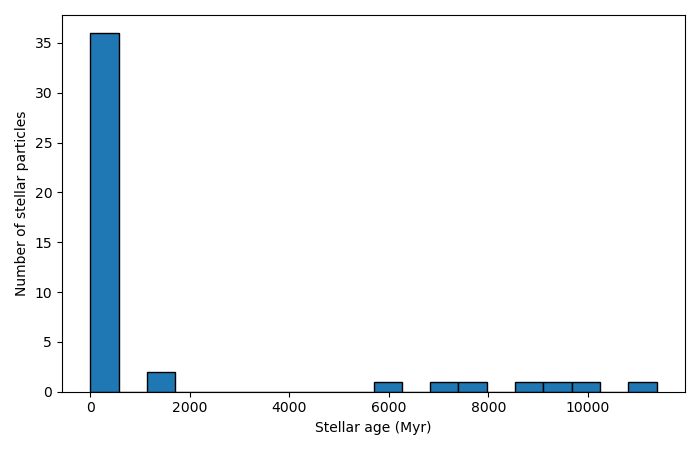

1443.2383680555556


In [43]:
from astropy.cosmology import FlatLambdaCDM
## peak 7 in 101509 specific stellar component analysis
cosmo = FlatLambdaCDM(H0=67.74, Om0=0.3089)

stars7 = load_peak_component(101509, 7, "stars")

r = np.linalg.norm(stars7["pos"], axis=1)
mask = r < 3.0

a_form = stars7["formation"][mask]
masses = stars7["mass"][mask]

# Use exact snapshot scale factor
a_snapshot = float(stars7["scale_factor"])
z_snapshot = 1 / a_snapshot - 1

z_form = 1 / a_form - 1

ages_myr = (
    cosmo.age(z_snapshot).value -
    cosmo.age(z_form).value
) * 1000

print(f"Snapshot redshift: {z_snapshot:.6f}")
print(f"Median stellar age: {np.median(ages_myr):.1f} Myr")

for limit in [10, 50, 100, 500]:
    young = ages_myr < limit
    print(
        f"Younger than {limit} Myr: "
        f"{young.sum()}/{len(ages_myr)} particles, "
        f"{100 * masses[young].sum()/masses.sum():.1f}% "
        f"of current stellar mass"
    )

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(ages_myr, bins=20, edgecolor="black")
ax.set_xlabel("Stellar age (Myr)")
ax.set_ylabel("Number of stellar particles")
plt.tight_layout()
plt.show()

print(ages_myr.sum()/len(ages_myr))

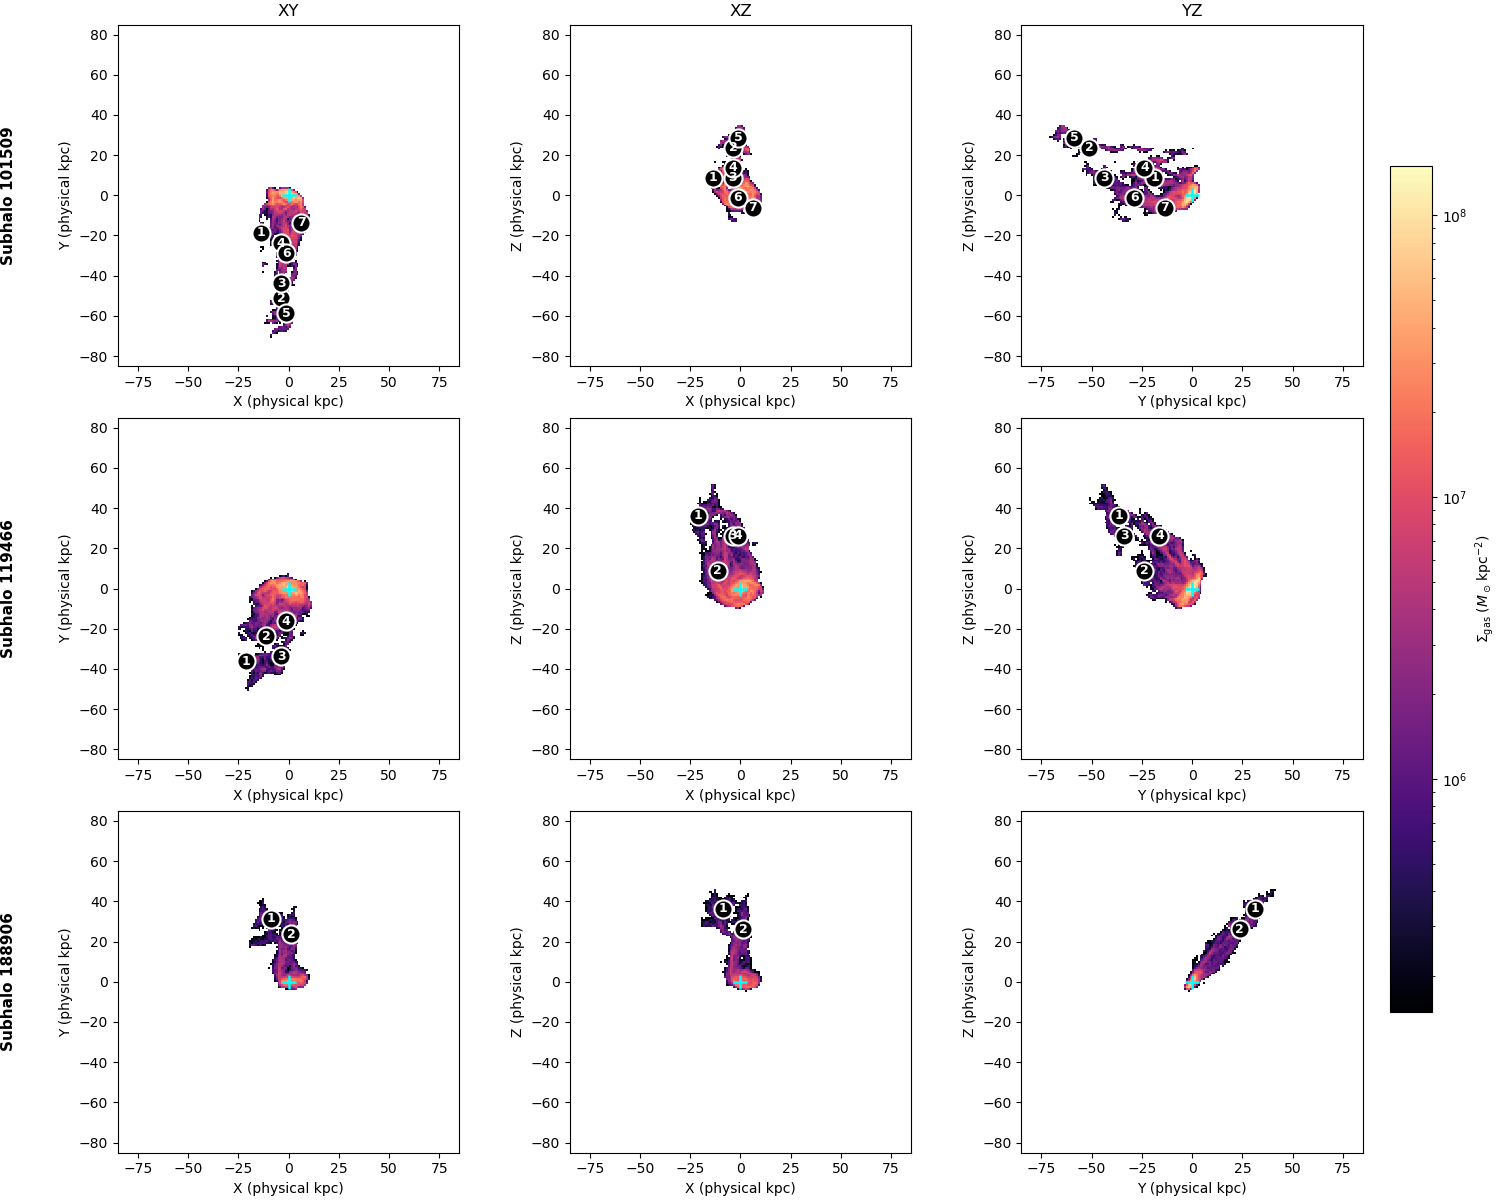

In [44]:
def plot_all_peaks(galaxy_ids, extent=85, bins=180):

    projections = [
        (0, 1, "X", "Y"),
        (0, 2, "X", "Z"),
        (1, 2, "Y", "Z")
    ]

    galaxy_ids = [int(gid) for gid in galaxy_ids]

    # Collect all surface-density maps first
    # to establish one shared colour scale
    maps = {}

    edges = np.linspace(-extent, extent, bins + 1)
    pixel_area = (edges[1] - edges[0])**2

    for gid in galaxy_ids:
        gas = gasses[gid]
        gas_pos = gas[["x", "y", "z"]].to_numpy()
        gas_mass = gas["Mass"].to_numpy()

        for col, (i, j, _, _) in enumerate(projections):
            hist, _, _ = np.histogram2d(
                gas_pos[:, i],
                gas_pos[:, j],
                bins=[edges, edges],
                weights=gas_mass
            )

            maps[gid, col] = hist.T / pixel_area

    # Shared logarithmic normalization
    positive = np.concatenate([
        m[m > 0] for m in maps.values()
    ])

    norm = LogNorm(
        vmin=max(np.percentile(positive, 5), 1),
        vmax=positive.max()
    )

    fig, axes = plt.subplots(
        len(galaxy_ids), 3,
        figsize=(15, 12),
        layout="constrained"
    )

    for row, gid in enumerate(galaxy_ids):
        coordinates = np.asarray(peaks[gid])

        for col, (i, j, xlabel, ylabel) in enumerate(projections):
            ax = axes[row, col]

            image = ax.imshow(
                np.ma.masked_less_equal(maps[gid, col], 0),
                origin="lower",
                extent=[-extent, extent, -extent, extent],
                cmap="magma",
                norm=norm,
                interpolation="nearest"
            )

            # Parent galaxy centre
            ax.scatter(
                0, 0,
                marker="+",
                s=100,
                linewidths=1.8,
                c="cyan",
                zorder=10
            )

            # Number and outline each peak
            for number, point in enumerate(coordinates, start=1):
                x, y = point[i], point[j]

                ax.scatter(
                    x, y,
                    s=170,
                    c="black",
                    edgecolors="white",
                    linewidths=1.5,
                    zorder=11
                )

                ax.annotate(
                    str(number),
                    (x, y),
                    ha="center",
                    va="center",
                    color="white",
                    fontsize=9,
                    fontweight="bold",
                    zorder=12
                )

                ax.set_xlabel(f"{xlabel} (physical kpc)")
                ax.set_ylabel(f"{ylabel} (physical kpc)")
                ax.set_xlim(-extent, extent)
                ax.set_ylim(-extent, extent)
                ax.set_aspect("equal")

            # Projection labels above the first row
            if row == 0:
                ax.set_title(
                    ["XY", "XZ", "YZ"][col],
                    fontsize=12
                )

            # Vertical subhalo label for each row
            if col == 0:
                ax.annotate(
                    f"Subhalo {gid}",
                    xy=(-0.32, 0.5),
                    xycoords="axes fraction",
                    rotation=90,
                    ha="center",
                    va="center",
                    fontsize=11,
                    fontweight="bold",
                    annotation_clip=False
                )

    # One shared colourbar
    fig.colorbar(
        image,
        ax=axes.ravel().tolist(),
        label=r"$\Sigma_{\rm gas}$ "
              r"($M_\odot\,\mathrm{kpc}^{-2}$)",
        shrink=0.75,
        pad=0.02
    )

    # Shared legend
    handles = [
        Line2D([], [], marker="+", linestyle="None",
               color="cyan", markersize=9,
               label="Parent galaxy centre"),
        Line2D([], [], marker="o", linestyle="None",
               markerfacecolor="none", markeredgecolor="lime",
               markersize=7, label="Density maximum")
    ]

    fig.legend(
        handles=handles,
        loc="lower center",
        ncol=2,
        bbox_to_anchor=(0.5, -0.025),
        frameon=False
    )

    fig.savefig(
        "all_galaxy_density_peaks.pdf",
        bbox_inches="tight"
    )

    plt.show()


plot_all_peaks([101509, 119466, 188906])


In [45]:
def measure_kinematics(gid, peak_number, radius=3):

    output = {
        "Galaxy": gid,
        "Peak": peak_number
    }

    for component in ["gas", "stars"]:

        data = load_peak_component(
            gid, peak_number, component
        )

        positions = data["pos"]
        velocities = data["vel"]
        masses = data["mass"]

        mask = np.linalg.norm(
            positions, axis=1
        ) < radius

        positions = positions[mask]
        velocities = velocities[mask]
        masses = masses[mask]

        output[f"N_{component}"] = len(masses)


    return output


kinematic_results = pd.DataFrame([
    measure_kinematics(gid, i + 1)
    for gid, positions in peaks.items()
    for i in range(len(positions))
])

display(kinematic_results)


,Galaxy,Peak,N_gas,N_stars
0,188906,1,244,0
1,188906,2,487,1
2,119466,1,512,3
3,119466,2,166,1
4,119466,3,230,1
5,119466,4,695,2
6,101509,1,425,4
7,101509,2,612,5
8,101509,3,715,5
9,101509,4,996,7
